In [ ]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

import optuna
from optuna.samplers import TPESampler

from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, Ridge

from causalml.inference.meta import BaseXRegressor
import lightgbm as lgb

from datetime import datetime, timedelta
from joblib import Parallel, delayed

import traceback
import warnings
import contextlib
import os
import re

pd.set_option('display.max_columns', None)
# Suppress LightGBM's verbose output during grid search
warnings.filterwarnings("ignore", category=UserWarning)
mpl.rcParams.update(mpl.rcParamsDefault)

# Functions

## Essential Functions

In [2]:
def eli_same_cols(df,cols,cols_num):
    to_exclude1 = []
    to_exclude2 = []
    aux = df[cols].copy()
    for i in cols:
        if aux[i].nunique() < 2:
            to_exclude1.append(i)

    aux2 = df[cols_num].copy()
    for i in cols_num:
        if aux2[i].nunique() < 2:
            to_exclude2.append(i)
    
    [cols.remove(i) for i in to_exclude1]
    aux = df[cols].copy()
    for i in cols:
        aux[i] = LabelEncoder().fit_transform(aux[i])

    aux = aux.corr('spearman')
    l = {}
    for i in aux.columns:
        l[i] = list(aux[aux[i] == 1][i].index)
        l[i].remove(i)

    to_include = []
    for i in l.keys():
        if len(l[i]) == 0:
            to_include.append(i)
        elif i not in to_exclude1:
            to_include.append(i)
            for j in l[i]:
                to_exclude1.append(j)

    return to_exclude1+to_exclude2

In [3]:
def create_matrix_case(df_log, case_col, target_col, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols):
    df_log[target_col] = df_log[target_col].astype(int)
    df_dummies = pd.get_dummies(df_log, columns=dynamic_cat_cols, dtype=int)
    
    dummy_cols = [col for col in df_dummies.columns if col not in [case_col, target_col] + static_cols + dynamic_num_cols_sum + dynamic_num_cols_max]

    agg_dict = {target_col: 'max'}
    
    for col in static_cols:
        agg_dict[col] = 'first'
        
    for col in dynamic_num_cols_sum:
        agg_dict[col] = 'sum'
        
    for col in dynamic_num_cols_max:
        agg_dict[col] = 'max'
        
    for col in dummy_cols:
        agg_dict[col] = 'max'

    case_matrix = df_dummies.groupby(case_col).agg(agg_dict).reset_index()
    
    return case_matrix

In [4]:
def data_preparation(df_full,case_col,target_col,feature_cols, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols):

    # taking data chunk wanted
    df = df_full[[case_col]+[target_col]+feature_cols]
    
    # identifying and eliminating columns that are colinear
    to_eli = eli_same_cols(df,list(df.select_dtypes(include=['str']).columns),list(df.select_dtypes(include=['int','float']).columns))
    df = df.drop(columns=to_eli)

    # finding all process variants
    encoder_activity = LabelEncoder()
    df['Activity_Encoded'] = encoder_activity.fit_transform(df['Activity'])

    df = df.merge(df.groupby(case_col)['Activity'].agg(list).reset_index().rename(columns={'Activity':'trace'}),on=case_col,how='left')

    encoder_variant = LabelEncoder()
    df['variante'] = encoder_variant.fit_transform(df['trace'].astype(str))

    # calculating variant statistics
    aux1 = df.groupby([case_col])[['variante',target_col]].agg('max').reset_index()
    aux2 = df.groupby([case_col])['variante'].agg('max').reset_index()['variante'].value_counts().reset_index()

    aux1 = pd.crosstab(aux1['variante'], aux1[target_col], normalize='index')
    aux1.columns = ['False_Percent', 'percentage_broken_SLA']
    aux1 = aux1.reset_index()
    aux1 = aux1.merge(aux2,on='variante',how='left').sort_values(by='count',ascending=False)

    # separating only the variants that have instances of SLA breach or account for at least 0.1% of the cases
    vari = aux1[(aux1['percentage_broken_SLA'] > 0) | (aux1['count'] > np.floor(df[case_col].nunique()/1000))]['variante'].to_list()

    # filtrating the variants from the dataframe
    df_filtered = df[df['variante'].isin(vari)].reset_index(drop=True)
    df_filtered[target_col] = df_filtered[target_col].astype(int)
    print('Number of events, cases and variants')
    print('Before variants filter:')
    print(len(df),df[case_col].nunique(),df['variante'].nunique())
    print('After variants filter:')
    print(len(df_filtered),df_filtered[case_col].nunique(),df_filtered['variante'].nunique())

    for i in df_filtered.columns[:-2]:
        if df_filtered[i].nunique() < 2:
            df_filtered = df_filtered.drop(columns=i)

    # making the dataframes for the explanation and prediction models
    used_attributes1 = list(df_filtered.columns[:-3])

    print(used_attributes1)

    df_filtered1 = df_filtered[used_attributes1]

    cat_cols = list(df_filtered1.select_dtypes(include=['str']).columns)
    cat_cols.remove(case_col)

    num_cals = list(df_filtered1.select_dtypes(include=['int','float']).columns)
    num_cals.remove(target_col)

    matrix_cases = create_matrix_case(df_filtered1,case_col, target_col, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols)

    matrix_cases.columns = matrix_cases.columns.str.replace(r'[^\w]', ' ', regex=True)


    return df_filtered1, matrix_cases

In [ ]:
def create_objective(X, y, num_cals, model_type='propensity'):

    n_positives = np.sum(y == 1)
    if n_positives < 2:
        def bypass_objective(trial):
            return 1e-6 
        return bypass_objective
    
    valid_splits = min(3, int(n_positives))

    if model_type == 'propensity':
        def objective(trial):
            param = {
                'objective': 'binary',
                'n_estimators': trial.suggest_int("n_estimators", 100, 1000),
                'learning_rate': trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                "max_depth": trial.suggest_int("max_depth", 4, 20),
                'num_leaves': trial.suggest_int("num_leaves", 10, 50), # Keep this low!

                # Phase 2: Overfitting Control
                'min_child_samples': trial.suggest_int("min_child_samples", 30, 200), # Keep this high!
                'subsample': trial.suggest_float('subsample', 0.6, 1),
                'subsample_freq': 1,           # Required to make subsample work
                'colsample_bytree': trial.suggest_float("colsample_bytree", 0.6, 1), # Keep this high!
                'scale_pos_weight': trial.suggest_int('scale_pos_weight', 1, 5),   
                
                # Phase 3: Regularization (L1 is great for sparse matrices)
                "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
                "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
                "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
                
                # System settings
                'random_state': 0,
                'verbose': -1,
                'n_jobs': 1                    
            }

            # Ensure num_leaves is strictly less than 2^(max_depth) to prevent errors/overfitting
            max_leaves = (2 ** param['max_depth']) - 1
            if param['num_leaves'] > max_leaves:
                param['num_leaves'] = max_leaves
            
            cv = StratifiedKFold(n_splits=valid_splits, shuffle=True, random_state=0)

            # Instantiate the model
            model = lgb.LGBMClassifier(**param)
            
            preprocessor = ColumnTransformer(transformers=[('num_scaler', MinMaxScaler(), num_cals)],
                                                remainder='passthrough')

            preprocessor.set_output(transform="pandas")

            pepeline = Pipeline([('preprocessor', preprocessor),
                                        ('model', model)])
            
            # 3. Run Cross-Validation silently
            cv_results = cross_validate(
                estimator=pepeline,
                X=X, 
                y=y, 
                cv=cv,
                scoring='neg_log_loss',
                n_jobs=-1
            )

            return -cv_results['test_score'].mean()

    if model_type == 'outcome':
        def objective(trial):
            # 1. Define the search space targeting sparse, imbalanced data
            param = {
                "objective": "binary", # X-Learner requires regressors even for binary outcomes
                "metric": "rmse",

                'n_estimators': trial.suggest_int("n_estimators", 100, 1000),
                'learning_rate': trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                "max_depth": trial.suggest_int("max_depth", 4, 20),
                'num_leaves': trial.suggest_int("num_leaves", 10, 50), # Keep this low!

                # Phase 2: Overfitting Control
                'min_child_samples': trial.suggest_int("min_child_samples", 30, 200), # Keep this high!
                'subsample': trial.suggest_float('subsample', 0.6, 1),
                'subsample_freq': 1,           # Required to make subsample work
                'colsample_bytree': trial.suggest_float("colsample_bytree", 0.6, 1), # Keep this high!
                
                # Phase 3: Regularization (L1 is great for sparse matrices)
                "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
                "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
                "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
                
                # System settings
                'random_state': 0,
                'verbose': -1,
                'n_jobs': 1                    
            }

            # Ensure num_leaves is strictly less than 2^(max_depth) to prevent errors/overfitting
            max_leaves = (2 ** param['max_depth']) - 1
            if param['num_leaves'] > max_leaves:
                param['num_leaves'] = max_leaves

            # 2. Use cross-validation to evaluate the parameters
            # We use StratifiedKFold to ensure the 5% minority class is present in every fold
            cv = StratifiedKFold(n_splits=valid_splits, shuffle=True, random_state=0)

            # Instantiate the model
            model = lgb.LGBMRegressor(**param)
            
            preprocessor = ColumnTransformer(transformers=[('num_scaler', MinMaxScaler(), num_cals)],
                                                remainder='passthrough')

            preprocessor.set_output(transform="pandas")

            pepeline = Pipeline([('preprocessor', preprocessor),
                                        ('model', model)])

            # 3. Run Cross-Validation silently
            cv_results = cross_validate(
                estimator=pepeline,
                X=X, 
                y=y, 
                cv=cv,
                scoring='neg_root_mean_squared_error',
                n_jobs=-1
            )

            return -cv_results['test_score'].mean()
    
    return objective

In [6]:
def parse_generic_treatment(treatment_dummy_name, original_features):
    """
    Translates a dummy column name into an actionable condition.
    Returns: (base_feature_name, treatment_type, condition_value)
    """
    base_feature = None
    clean_base_feature = None
    
    # 1. Find which original feature this dummy belongs to by simulating the regex cleaning
    for feature in original_features:
        # Replicate the column cleaning applied in data_preparation
        clean_feature = re.sub(r'[^\w]', ' ', feature)
        
        if treatment_dummy_name.startswith(f"{clean_feature}_"):
            base_feature = feature         # The raw name (e.g., 'Man-Hour Cost')
            clean_base_feature = clean_feature # The safe name (e.g., 'Man Hour Cost')
            break
            
    if not base_feature:
        raise ValueError(f"Could not map dummy '{treatment_dummy_name}' to base feature.")

    # 2. Extract the value part of the dummy (e.g., "High", "A5", "E12")
    # Use the length of the cleaned feature name to slice correctly
    value_suffix = treatment_dummy_name[len(clean_base_feature) + 1:]
    
    return base_feature, 'categorical', value_suffix

In [ ]:
def get_treatment_trigger_indices(event_log, case_col, treatment_dummy_name, original_features, dynamic_num_cols_sum, dynamic_num_cols_max):
    """
    Scans the raw event log to find the exact event index where the treatment condition
    was first met for each case.
    
    Returns:
        dict: A mapping of {case_id: first_trigger_index} only for cases that received the treatment.
    """
    # 1. Translate the dummy variable into a mathematical/logical rule
    base_feat, t_type, condition = parse_generic_treatment(treatment_dummy_name, original_features)
    
    trigger_indices = {}
    
    # The pandas index is already chronologically ordered, and groupby preserves this row order.
    for case_id, case_group in event_log.groupby(case_col):
        trigger_events = pd.DataFrame()
        
        # 3a. Handle Categorical Treatments (e.g., Activity == 'A5', Executor == 'E12')
        if t_type == 'categorical':
            trigger_events = case_group[case_group[base_feat] == condition]
        
        # 4. If the case met the treatment condition, record the index of the FIRST occurrence
        if not trigger_events.empty:
            # We capture the original DataFrame index so we can slice exactly at this row later
            first_trigger_idx = trigger_events.index[0]
            trigger_indices[case_id] = first_trigger_idx
            
    return trigger_indices

In [8]:
def align_and_truncate_event_log(event_log, case_col, treated_trigger_indices, random_seed=0):
    """
    Truncates treated cases exactly at the treatment event.
    Aligns control cases by sampling truncation lengths from the treated distribution.
    """
    np.random.seed(random_seed)
    
    truncated_case_chunks = []
    treated_ptb_lengths = []
    
    grouped = event_log.groupby(case_col)

    all_case_ids = sorted(list(event_log[case_col].unique()))
    treated_case_ids = sorted(list(treated_trigger_indices.keys()))
    control_case_ids = sorted(list(set(all_case_ids) - set(treated_case_ids)))
    
    # 1. TRUNCATE TREATED GROUP & BUILD DISTRIBUTION
    for case_id in treated_case_ids:
        group = grouped.get_group(case_id)
        trigger_idx = treated_trigger_indices[case_id]
        
        # Isolate the Pre-Treatment Baseline (everything BEFORE the trigger)
        ptb_slice = group.loc[:trigger_idx - 1] 
        
        # Record the temporal maturity of this case
        ptb_length = len(ptb_slice)
        if ptb_length > 0:
            treated_ptb_lengths.append(ptb_length)
            truncated_case_chunks.append(ptb_slice)

    # Safety net: If no valid treated lengths exist, default to 1
    if not treated_ptb_lengths:
        treated_ptb_lengths = [1]

    # 2. ALIGN CONTROL GROUP
    for case_id in control_case_ids:
        group = grouped.get_group(case_id)
        
        # Sample a temporal maturity matched to the treated distribution
        sampled_length = np.random.choice(treated_ptb_lengths)
        
        # Constraint: Control cases cannot be longer than their actual life.
        max_safe_length = max(1, len(group) - 1)
        final_length = min(sampled_length, max_safe_length)
        
        # Slice the control case purely by position (.iloc)
        ptb_slice = group.iloc[:final_length]
        truncated_case_chunks.append(ptb_slice)
        
    # --- FIX: Return empty DataFrame safely if no chunks exist ---
    if not truncated_case_chunks:
        return pd.DataFrame(columns=event_log.columns)
        
    return pd.concat(truncated_case_chunks).reset_index(drop=True)

In [ ]:
def get_causality_of_rules_with_intervention(df, rules_df, case_col, num_cols, treatment_col, target_col, base_feature=None):
    """
    Evaluates the causal effect of a specific treatment.
    Explicitly calculates the Global ATE first, then evaluates the sub-populations.
    Includes Linear Extrapolation for the control outcome to survive extreme selection bias.
    """
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    results_list = []

    # 1. Isolate the Treatment Array (T) and Target (y)
    T_global = df[treatment_col].fillna(0).astype(int) 
    y_global = df[target_col]
    
    # 2. Clean X: Remove treatment AND base continuous feature to prevent data leakage
    features_to_drop = [treatment_col, case_col, target_col]
    if base_feature and base_feature != treatment_col:
        features_to_drop.extend([c for c in df.columns if c.startswith(f"{base_feature}_") or c == base_feature])
        
    features_to_use = [c for c in df.columns if c not in features_to_drop]
    X_global = df[features_to_use]
    num_cols_clean = [c for c in num_cols if c not in features_to_drop]

    # --- INTERNAL HELPER FUNCTION FOR CLEANER CODE ---
    def _calculate_causal_math(X_sub, y_sub, T_sub):
        """Runs checks and executes the Optuna X-Learner loop with Ridge extrapolation."""
        # A: Check Positivity
        if T_sub.nunique() < 2 or len(T_sub) < 10:
            return np.nan, np.nan, np.nan, "Positivity Violation (Not enough treatment variation)"
        
        # B: Check Perfect Separation
        y_t0, y_t1 = y_sub[T_sub == 0], y_sub[T_sub == 1]
        if y_t0.nunique() < 2 or y_t1.nunique() < 2:
            return np.nan, np.nan, np.nan, "Perfect Separation (Zero variance in SLA breach for an arm)"

        fixed_sampler = TPESampler(seed=0)
        try:
            # Propensity Model (Tuned via Optuna)
            study_p = optuna.create_study(direction='minimize', sampler=fixed_sampler)
            study_p.optimize(create_objective(X_sub, T_sub, num_cols_clean, model_type='propensity'), n_trials=50, show_progress_bar=False)
            best_p_model = lgb.LGBMClassifier(**study_p.best_params, objective='binary', random_state=0, verbose=-1, n_jobs=-1)
            best_p_model.fit(X_sub, T_sub)
            p_scores = best_p_model.predict_proba(X_sub)[:, 1]

            # --- DEFENSE: Linear Extrapolation for Control Outcome ---
            # Replaces the LightGBM model with Ridge to handle counterfactual outliers
            best_t0_model = Ridge(alpha=1.0, random_state=0)

            # Treatment Outcome Model (Tuned via Optuna)
            X_t1 = X_sub[T_sub == 1]
            study_t1 = optuna.create_study(direction='minimize', sampler=fixed_sampler)
            study_t1.optimize(create_objective(X_t1, y_t1, num_cols_clean, model_type='outcome'), n_trials=50, show_progress_bar=False)
            best_t1_model = lgb.LGBMRegressor(**study_t1.best_params, objective='binary', random_state=0, verbose=-1, n_jobs=-1)

            # Hybrid X-Learner
            x_learner_tuned = BaseXRegressor(
                learner=lgb.LGBMRegressor(random_state=0, verbose=-1),
                control_outcome_learner=best_t0_model,       
                treatment_outcome_learner=best_t1_model,
                control_effect_learner=lgb.LGBMRegressor(random_state=0, verbose=-1),
                treatment_effect_learner=lgb.LGBMRegressor(random_state=0, verbose=-1)
            )

            ate, lb, ub = x_learner_tuned.estimate_ate(X=X_sub, treatment=T_sub, y=y_sub, p=p_scores)
            return ate[0], lb[0], ub[0], "Success"
        except Exception as e:
            return np.nan, np.nan, np.nan, f"Error calculating ATE: {e}"
    # --------------------------------------------------

    # 3. EXPLICITLY CALCULATE GLOBAL ATE FIRST
    print(f"  Evaluating Global ATE (Entire Dataset)...")
    ate, lb, ub, msg = _calculate_causal_math(X_global, y_global, T_global)
    
    global_dict = {
        'Rule': 'Global ATE (Entire Dataset)',
        'Node_Samples': len(df),
        'Support': 1.0,
        'Confidence False': 1 - y_global.mean(),
        'Confidence True': y_global.mean(),
        'Lift True': 1.0,
        'Causal Effect (ATE)': ate,
        '95% Confidence Interval': [lb, ub]
    }
    results_list.append(global_dict)
    
    if msg == "Success":
        print(f"    -> Global ATE: {ate:.4f}")
    else:
        print(f"    -> Skipping Global: {msg}")

    # 4. ITERATE THROUGH SPECIFIC FILTERED RULES
    for idx, row in rules_df.iterrows():
        raw_rule = row['Rule']
        row_dict = row.to_dict() 
        
        # Skip Root if it somehow survived the filter
        if raw_rule == "Root":
            continue
            
        print(f"  Evaluating Rule: {raw_rule[:80]}...") 
        clean_rule = raw_rule.replace("'", "`").replace(" AND ", " and ")
        
        mask = df.eval(clean_rule)

        # TRUE SUPPORT CALCULATION
        actual_node_samples = mask.sum()
        row_dict['Node_Samples'] = actual_node_samples
        row_dict['Support'] = actual_node_samples / len(df)
        
        # Capture how many cases in this rule were actually treated
        row_dict['Treated_in_Node'] = T_global[mask].sum()
        row_dict['Control_in_Node'] = actual_node_samples - row_dict['Treated_in_Node']
        
        # Calculate Causal math for this specific leaf
        ate, lb, ub, msg = _calculate_causal_math(X_global[mask], y_global[mask], T_global[mask])
        
        row_dict['Causal Effect (ATE)'] = ate
        row_dict['95% Confidence Interval'] = [lb, ub]
        results_list.append(row_dict)
        
        if msg == "Success":
            print(f"    -> ATE: {ate:.4f}")
        else:
            print(f"    -> Skipping: {msg}")

    return pd.DataFrame(results_list)

In [10]:
def extract_surrogate_rules(tree_model, feature_names):
    """Extracts business rules from the CATE Surrogate Regression Tree."""
    tree_ = tree_model.tree_
    rules = []
    
    def traverse(node_id, current_path_str, current_conditions):
        # Leaf Node
        if tree_.children_left[node_id] == tree_.children_right[node_id]:
            n_samples = tree_.n_node_samples[node_id]
            pred_cate = tree_.value[node_id][0][0] # Continuous causal impact
            
            rules.append({
                'Rule': " AND ".join(current_path_str) if current_path_str else "Root",
                'Conditions': current_conditions,
                'Predicted_CATE_Surrogate': pred_cate,
                'Node_Samples': n_samples
            })
            return
            
        feature = feature_names[tree_.feature[node_id]]
        threshold = tree_.threshold[node_id]
        
        # Use backticks (`) to ensure pandas.eval natively handles spaces in column names
        traverse(tree_.children_left[node_id], 
                 current_path_str + [f"`{feature}` <= {threshold:.5f}"],
                 current_conditions + [{'feature': feature, 'operator': '<=', 'threshold': threshold}])
        
        traverse(tree_.children_right[node_id], 
                 current_path_str + [f"`{feature}` > {threshold:.5f}"],
                 current_conditions + [{'feature': feature, 'operator': '>', 'threshold': threshold}])

    traverse(0, [], [])
    df_rules = pd.DataFrame(rules)
    if not df_rules.empty:
        return df_rules.sort_values(by='Predicted_CATE_Surrogate', ascending=False).reset_index(drop=True)
    return df_rules

In [ ]:
def generate_cate_surrogate_rules(df, treatment_col, target_col, num_cols):
    """Calculates Individual CATEs and groups them via a Surrogate Tree."""
    X = df[num_cols]
    T = df[treatment_col].fillna(0).astype(int)
    y = df[target_col]

    size_data = len(X)
    
    lgb_params = {
        'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5,
        'num_leaves': 31, 'min_child_samples': 20, 'random_state': 0,
        'verbose': -1, 'n_jobs': 1 
    }
    
    try:
        # A. Propensity Modeling & Trimming
        propensity_model = lgb.LGBMClassifier(**lgb_params, objective='binary')
        propensity_model.fit(X, T)
        p_scores = propensity_model.predict_proba(X)[:, 1]
        
        support_mask = (p_scores >= 0.05) & (p_scores <= 0.95)
        if support_mask.sum() < 30:
            return pd.DataFrame()
            
        # BUGFIX: Use .values to prevent CausalML/Scikit-Learn Index Out-of-Bounds crashes
        X_trim_arr = X[support_mask].values
        T_trim_arr = T[support_mask].values
        y_trim_arr = y[support_mask].values
        p_trim_arr = p_scores[support_mask]
        
        tree_model = lgb.LGBMRegressor(**lgb_params, objective='regression')
        
        # B. CausalML X-Learner 
        x_learner = BaseXRegressor(
            learner=tree_model,
            control_outcome_learner=Ridge(alpha=1.0, random_state=0),
            treatment_outcome_learner=tree_model,
            control_effect_learner=tree_model,
            treatment_effect_learner=tree_model
        )
        
        # C. Predict Individual CATEs
        cate_preds = x_learner.fit_predict(X=X_trim_arr, treatment=T_trim_arr, y=y_trim_arr, p=p_trim_arr)
        cate_preds = cate_preds.flatten()
        
        # D. Train the Surrogate Profiler Tree
        surrogate_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=int(size_data*0.05), random_state=0)
        
        # Ensure we fit on the dataframe so extract_surrogate_rules maps the feature names correctly
        surrogate_tree.fit(X[support_mask], cate_preds)
        
        return extract_surrogate_rules(surrogate_tree, num_cols)
        
    except Exception as e:
        print(f"      -> Surrogate Generation Error: {e}")
        traceback.print_exc()
        return pd.DataFrame()

In [ ]:
def run_causal_discovery_pipeline(
    df_raw_log, df_discovery, target_col, case_col, original_features, 
    static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols, candidate_prefixes=['Activity_', 'Executor_', 'Spurious_Tag_'], invalid_contexts=['Executor_', 'Requester_', 'Resposible For Alteration_'], top_n=10, top_pct=10
):
    print("--- PHASE 1: Treatment Discovery (Iterative Marginal LR) ---")
    valid_treatments = test_lr_feature_selection(
        df_discovery, case_col, target_col, 
        candidate_prefixes=candidate_prefixes, top_n=top_n, top_pct=top_pct
    )
    print(f"Discovered {len(valid_treatments)} top candidate interventions.")

    print(valid_treatments)
    
    all_causal_results = []
    
    print("\n--- PHASE 2 & 3: Temporal Truncation & CATE Surrogate Profiling ---")
    for treatment_dummy in valid_treatments:
        print(f"\n>> Evaluating Intervention: {treatment_dummy}")
        
        try:
            base_feat, _, _ = parse_generic_treatment(treatment_dummy, original_features)
        except ValueError:
            continue
            
        # A. Temporal Truncation
        trigger_indices = get_treatment_trigger_indices(
            df_raw_log, case_col, treatment_dummy, original_features, dynamic_num_cols_sum, dynamic_num_cols_max
        )
        df_log_truncated = align_and_truncate_event_log(df_raw_log, case_col, trigger_indices)
        
        if df_log_truncated.empty:
            print(f"    -> [DISCARDED] Triggers too early (Environmental proxy).")
            continue
        
        # B. Build Unbiased Pre-Treatment Baseline Matrix
        df_estimation = create_matrix_case(
            df_log_truncated, case_col, target_col, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
        )
        # BUGFIX: DEFRAGMENT DATAFRAME
        df_estimation = df_estimation.copy() 
        
        # C. Map the treatment vector (T) into the continuous estimation matrix
        df_estimation['Tested_Treatment'] = df_estimation[case_col].apply(lambda x: 1 if x in trigger_indices else 0)
        
        # D. Generate CATE Surrogate Rules
        # FIX: Isolate context features, strictly excluding high-cardinality IDs 
        # (Executors, Requesters) to prevent the Surrogate Tree from overfitting to noise.
        num_cols = [
            c for c in df_estimation.select_dtypes(include=['float', 'int']).columns 
            if c not in [target_col, 'Tested_Treatment', base_feat]
            and not c.startswith(tuple(invalid_contexts))
        ]
        
        print("    -> Generating Context Personas (Surrogate Tree)...")
        top_context_rules = generate_cate_surrogate_rules(
            df_estimation, 'Tested_Treatment', target_col, num_cols
        )
        
        if top_context_rules.empty:
            print("    -> [SKIPPED] Could not map sufficient common support.")
            continue
            
        # E. Rigorous Confidence Interval Evaluation via Optuna Engine
        # Pass df_binned=None so the engine natively executes the continuous rules generated by the Surrogate Tree
        causal_results_df = get_causality_of_rules_with_intervention(
            df=df_estimation, 
            rules_df=top_context_rules, 
            case_col=case_col,
            num_cols=num_cols, 
            treatment_col='Tested_Treatment',
            target_col=target_col,
            base_feature=base_feat 
        )
        
        if not causal_results_df.empty:
            causal_results_df['Tested_Treatment'] = treatment_dummy
            causal_results_df['Base_Feature'] = base_feat
            all_causal_results.append(causal_results_df)

    # FINAL REPORT COMPILATION
    if all_causal_results:
        final_results = pd.concat(all_causal_results, ignore_index=True)
        cols = ['Tested_Treatment', 'Base_Feature', 'Rule', 'Causal Effect (ATE)', '95% Confidence Interval', 'Node_Samples'] 
        cols += [c for c in final_results.columns if c not in cols]
        
        final_results = final_results[cols]
        # Keep only the rows where the Math Engine succeeded
        return final_results[~final_results['Causal Effect (ATE)'].isnull()].reset_index(drop=True)
    else:
        return pd.DataFrame()

## Synthetic Log Generators

In [ ]:
def generate_benchmarked_complex_log(n_cases=1000, confounding_strength=0.8, rework_probability=0.2, causal_noise=0.1, executor_cardinality=50, requesters_cardinality=10, responsibles_cardinality=50, random_state=0):
    np.random.seed(random_state)
    events = []
    ground_truth = []
    
    executors_pool = [f'E{i}' for i in range(1, executor_cardinality + 1)]
    requesters_pool = [f'Req_{i}' for i in range(1, requesters_cardinality + 1)]
    responsibles_pool = [f'Resp_{i}' for i in range(1, responsibles_cardinality + 1)]
    
    activity_costs = {
        'A1': (1, 5), 'A2': (10, 25), 'A3': (5, 15), 'A4': (15, 30), 
        'A8': (10, 20), 'A9': (5, 10), 
        'A5': (20, 50), 'A6': (5, 15), 'A7': (10, 25), 'A10': (10, 20), 'A11': (15, 25), 'A12': (5, 15)
    }
    
    for i in range(n_cases):
        case_id = f'Case_{i:05d}'
        start_time = datetime(2026, 1, 1, 8, 0, 0) + timedelta(days=np.random.randint(0, 90))
        current_time = start_time
        
        impact = np.random.choice([1, 2, 3, 4, 5], p=[0.05, 0.15, 0.5, 0.2, 0.1])
        priority = np.random.choice([1, 2, 3, 4], p=[0.1, 0.3, 0.4, 0.2])
        requester = np.random.choice(requesters_pool)
        responsible = np.random.choice(responsibles_pool)
        
        trace = []
        def add_activity(act, cost_override=None):
            cost = cost_override if cost_override is not None else np.random.uniform(*activity_costs[act])
            trace.append((act, cost))

        add_activity('A1')
        if np.random.rand() < 0.6:
            add_activity('A2')
            while np.random.rand() < rework_probability:
                add_activity('A4') 
                add_activity('A2') 
        else:
            add_activity('A8')
            if np.random.rand() < 0.4:
                add_activity('A9')
        add_activity('A3')
        
        pre_treatment_cost = sum(cost for act, cost in trace)
        
        treatment_logit = confounding_strength * ((pre_treatment_cost - 50) / 15 + (impact - 3)) - 1
        has_treatment = np.random.rand() < (1 / (1 + np.exp(-treatment_logit)))
        
        expected_control_post_cost = 17.5 + 10 + 10 # Avg cost of A7 + A12 + A6
        
        # The true CATE is a property of the case, regardless of actual treatment assignment
        if pre_treatment_cost > 50:
            expected_treated_post_cost = 400 + 20 + 10 # Avg A5 + A11 + A6
        else:
            expected_treated_post_cost = 100 + 20 + 10
            
        true_cate = (expected_treated_post_cost - expected_control_post_cost) / 1000
        
        # Now apply the actual treatment flow
        if has_treatment:
            cost_A5 = np.random.uniform(350, 450) if pre_treatment_cost > 50 else np.random.uniform(50, 150)
            add_activity('A5', cost_override=cost_A5) 
            add_activity('A11') 
        else:
            add_activity('A7') 
            add_activity('A12')
            
        add_activity('A6')
        
        total_case_cost = sum(cost for act, cost in trace)
        
        # The probability of SLA breach is now driven by the TOTAL cost (introducing leakage risk)
        final_prob = 0.05 + (total_case_cost / 1000) + (impact * 0.02) + np.random.normal(0, causal_noise)
        is_breached = 1 if np.random.rand() < np.clip(final_prob, 0, 1) else 0
        
        ground_truth.append({
            'Requisition': case_id, 'Treatment_A5': int(has_treatment),
            'True_CATE': true_cate, 'Observed_Breach': is_breached
        })
        
        running_case_length = 0
        running_reatrib = 0
        for act, act_cost in trace:
            running_case_length += 1
            if act in ['A4', 'A9']: running_reatrib += 1
                
            duration = timedelta(hours=np.random.lognormal(mean=1.2, sigma=0.6))
            current_time += duration
            events.append({
                'Requisition': case_id, 'Activity': act,
                'Start': (current_time - duration).strftime('%Y-%m-%dT%H:%M:%S.000+0000'),
                'End': current_time.strftime('%Y-%m-%dT%H:%M:%S.000+0000'),
                'Executor': np.random.choice(executors_pool),
                'Man-Hour Cost': act_cost, 'Reatribution': running_reatrib,
                'SLA Breach': bool(is_breached), 'Impact': impact, 'Priority': priority,
                'Requester': requester, 'Resposible For Alteration': responsible,
                'case length': running_case_length 
            })
    return pd.DataFrame(events), pd.DataFrame(ground_truth)

In [14]:
def generate_advanced_test_log(
    n_cases=1000, 
    confounding_strength=0.8, 
    rework_probability=0.2, 
    causal_noise=0.1, 
    executor_cardinality=50,
    requesters_cardinality=10,
    responsibles_cardinality=50,
    random_state=0
):
    """
    Advanced synthetic log generator designed specifically to stress-test 
    treatment feature discovery and multi-conditional context discovery.
    
    New Injected Characteristics:
    1. Multi-conditional CATE (Context Discovery): True treatment effect 
       depends on a strict conjunction: (Pre_Treatment_Cost > 50) & (Priority <= 2).
    2. Competing Treatments (Feature Discovery): Introduces a choice between 
       Treatment A5 and Treatment A7 based on distinct logic paths.
    3. Spurious Correlation Injection: Injects a non-causal proxy feature 
       ('Spurious_Tag') heavily correlated with the outcome to test feature selection resilience.
    """
    np.random.seed(random_state)
    events = []
    ground_truth = []
    
    executors_pool = [f'E{i}' for i in range(1, executor_cardinality + 1)]
    requesters_pool = [f'Req_{i}' for i in range(1, requesters_cardinality + 1)]
    responsibles_pool = [f'Resp_{i}' for i in range(1, responsibles_cardinality + 1)]
    
    activity_costs = {
        'A1': (1, 5), 'A2': (10, 25), 'A3': (5, 15), 'A4': (15, 30), 
        'A8': (10, 20), 'A9': (5, 10), 'A5': (20, 50), 'A7': (10, 25), 
        'A6': (5, 15), 'A10': (10, 20), 'A11': (15, 25), 'A12': (5, 15)
    }
    
    for i in range(n_cases):
        case_id = f'Case_{i:05d}'
        start_time = datetime(2026, 1, 1, 8, 0, 0) + timedelta(days=np.random.randint(0, 90))
        current_time = start_time
        
        impact = np.random.choice([1, 2, 3, 4, 5], p=[0.05, 0.15, 0.5, 0.2, 0.1])
        priority = np.random.choice([1, 2, 3, 4], p=[0.1, 0.3, 0.4, 0.2])
        requester = np.random.choice(requesters_pool)
        responsible = np.random.choice(responsibles_pool)
        
        trace = []
        def add_activity(act, cost_override=None):
            cost = cost_override if cost_override is not None else np.random.uniform(*activity_costs[act])
            trace.append((act, cost))

        # --- PRE-TREATMENT FLOW ---
        add_activity('A1')
        if np.random.rand() < 0.6:
            add_activity('A2')
            while np.random.rand() < rework_probability:
                add_activity('A4') 
                add_activity('A2') 
        else:
            add_activity('A8')
            if np.random.rand() < 0.4:
                add_activity('A9')
        add_activity('A3')
        
        pre_treatment_cost = sum(cost for act, cost in trace)
        
        # --- TREATMENT ASSIGNMENT (Selection Bias) ---
        treatment_logit = confounding_strength * ((pre_treatment_cost - 50) / 15 + (impact - 3)) - 1
        has_treatment_a5 = np.random.rand() < (1 / (1 + np.exp(-treatment_logit)))

        # --- TRUE SPURIOUS CORRELATION INJECTION ---
        # Derived from the observed pre_treatment_cost. It will correlate heavily 
        # with the outcome, but does NOT exist in the final probability equation.
        spurious_tag = 1 if (pre_treatment_cost > 45 and np.random.rand() < 0.8) else 0
        
        # --- MULTI-CONDITIONAL CATE (Context Discovery Test) ---
        # True effect is heterogeneous based on TWO variables simultaneously: Cost and Priority
        if pre_treatment_cost > 50 and priority <= 2:
            true_cate = 0.50  # High impact sub-population
        elif pre_treatment_cost > 50 and priority > 2:
            true_cate = 0.25  # Moderate impact
        else:
            true_cate = 0.05  # Minimal impact
            
        expected_control_post_cost = 17.5 + 10 + 10 
        if pre_treatment_cost > 50:
            expected_treated_post_cost = 400 + 20 + 10 
        else:
            expected_treated_post_cost = 100 + 20 + 10
            
        # Apply actual treatment flow paths
        if has_treatment_a5:
            cost_A5 = np.random.uniform(350, 450) if pre_treatment_cost > 50 else np.random.uniform(50, 150)
            add_activity('A5', cost_override=cost_A5) 
            add_activity('A11') 
        else:
            add_activity('A7') 
            add_activity('A12')
            
        add_activity('A6')
        total_case_cost = sum(cost for act, cost in trace)

        # --- OUTCOME MATH ---
        # Strictly driven by actual cost and impact. Spurious_tag is omitted.
        final_prob = 0.05 + (total_case_cost / 1000) + (impact * 0.02) + np.random.normal(0, causal_noise)
        is_breached = 1 if np.random.rand() < np.clip(final_prob, 0, 1) else 0
        
        ground_truth.append({
            'Requisition': case_id, 
            'Treatment_A5': int(has_treatment_a5),
            'True_CATE': true_cate, 
            'Spurious_Tag': spurious_tag,
            'Observed_Breach': is_breached
        })
        
        running_case_length = 0
        running_reatrib = 0
        for act, act_cost in trace:
            running_case_length += 1
            if act in ['A4', 'A9']: 
                running_reatrib += 1
                
            duration = timedelta(hours=np.random.lognormal(mean=1.2, sigma=0.6))
            current_time += duration
            events.append({
                'Requisition': case_id, 
                'Activity': act,
                'Start': (current_time - duration).strftime('%Y-%m-%dT%H:%M:%S.000+0000'),
                'End': current_time.strftime('%Y-%m-%dT%H:%M:%S.000+0000'),
                'Executor': np.random.choice(executors_pool),
                'Man-Hour Cost': act_cost, 
                'Reatribution': running_reatrib,
                'SLA Breach': bool(is_breached), 
                'Impact': impact, 
                'Priority': priority,
                'Requester': requester, 
                'Resposible For Alteration': responsible,
                'case length': running_case_length,
                'Spurious_Tag': spurious_tag # Injected as an event-level or case attribute
            })
            
    return pd.DataFrame(events), pd.DataFrame(ground_truth)

## Discovery Benchmark

In [15]:
def test_lr_feature_selection(df, case_col, target_col, candidate_prefixes=['Activity_', 'Executor_', 'Spurious_Tag_'], top_n=20, top_pct=None):
    
    # Drop known downstream mediators
    mediators = [c for c in df.columns if 'Man Hour Cost' in c or 'case length' in c or 'Reatribution' in c]
    df_clean = df.drop(columns=[case_col] + mediators)
    y = df_clean[target_col]
    
    candidate_cols = [c for c in df_clean.columns if any(c.startswith(p) for p in candidate_prefixes)]
    context_cols = [c for c in df_clean.columns if c not in candidate_cols and c != target_col]
    
    # Override top_n if top_pct is provided
    if top_pct is not None:
        top_n = max(1, int(np.ceil(len(candidate_cols) * (top_pct / 100.0))))
    
    discovered_results = []
    
    for treatment in candidate_cols:
        if df_clean[treatment].mean() < 0.01:
            continue
            
        X_eval = df_clean[[treatment] + context_cols]
        
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_eval)
        
        # Standard L2 Penalty for stability
        model = LogisticRegression(l1_ratio=0, C=10.0, solver='liblinear', random_state=0, max_iter=500)
        model.fit(X_scaled, y)
        
        treatment_coef = model.coef_[0][0]
        discovered_results.append({
            'Treatment': treatment,
            'Absolute_Impact': abs(treatment_coef)
        })

    discovered_results = sorted(discovered_results, key=lambda x: x['Absolute_Impact'], reverse=True)
    return [item['Treatment'] for item in discovered_results[:top_n]]

In [16]:
def test_rf_feature_selection(df, case_col, target_col, candidate_prefixes=['Activity_', 'Executor_', 'Spurious_Tag_'], top_n=20, top_pct=None):
    
    # Drop known downstream mediators
    mediators = [c for c in df.columns if 'Man Hour Cost' in c or 'case length' in c or 'Reatribution' in c]
    df_discovery = df.drop(columns=[case_col] + mediators)
    
    X = df_discovery.drop(columns=[target_col])
    y = df_discovery[target_col]
    
    candidate_cols = [c for c in X.columns if any(c.startswith(p) for p in candidate_prefixes)]
    
    # Override top_n if top_pct is provided
    if top_pct is not None:
        top_n = max(1, int(np.ceil(len(candidate_cols) * (top_pct / 100.0))))
        
    # Note: n_jobs=1 prevents thread collision when run inside a parallel joblib loop
    rf = RandomForestClassifier(
        n_estimators=100, 
        max_depth=6, 
        class_weight='balanced', 
        random_state=0, 
        n_jobs=1 
    )
    rf.fit(X, y)
    
    importances = pd.Series(rf.feature_importances_, index=X.columns)
    
    # Sort and slice using dynamic top_n
    top_candidates = importances[candidate_cols].sort_values(ascending=False).head(top_n).index.tolist()
    return top_candidates

In [17]:
def test_iterative_tree_discovery(df, case_col, target_col, candidate_prefixes=['Activity_', 'Executor_', 'Spurious_Tag_'], top_n=20, top_pct=None):

    # Drop known downstream mediators
    mediators = [c for c in df.columns if 'Man Hour Cost' in c or 'case length' in c or 'Reatribution' in c]
    df_clean = df.drop(columns=[case_col] + mediators)
    y = df_clean[target_col]
    
    candidate_cols = [c for c in df_clean.columns if any(c.startswith(p) for p in candidate_prefixes)]
    context_cols = [c for c in df_clean.columns if c not in candidate_cols and c != target_col]
    
    # Override top_n if top_pct is provided
    if top_pct is not None:
        top_n = max(1, int(np.ceil(len(candidate_cols) * (top_pct / 100.0))))
        
    discovered_results = []
    
    for treatment in candidate_cols:
        if df_clean[treatment].mean() < 0.01:
            continue
            
        X_eval = df_clean[[treatment] + context_cols]
        
        clf = DecisionTreeClassifier(
            max_depth=4, 
            criterion='entropy', 
            class_weight='balanced', 
            random_state=0
        )
        clf.fit(X_eval, y)
        
        treatment_importance = clf.feature_importances_[0]
        discovered_results.append({
            'Treatment': treatment,
            'Tree_Importance': treatment_importance
        })

    discovered_results = sorted(discovered_results, key=lambda x: x['Tree_Importance'], reverse=True)
    return [item['Treatment'] for item in discovered_results[:top_n]]

In [18]:
def _run_single_experiment(
    seed, confounding, n_cases, case_col, target_col, top_n, top_pct,
    feature_cols, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
):
    """
    Isolated worker function for a single seed and confounding strength.
    Mutes standard print outputs to prevent notebook console spam during parallel execution.
    """
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull):
            
            # 1. Generate Data
            df_syn, df_syn_truth = generate_advanced_test_log(
                n_cases=n_cases, confounding_strength=confounding, random_state=seed
            )
            
            # 2. Prep Data
            df_syn_raw, df_syn_cases = data_preparation(
                df_syn, case_col, target_col, feature_cols, static_cols, 
                dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
            )
            
            prefixes = ['Activity_', 'Executor_', 'Resposible For Alteration_', 'Spurious_Tag']
            
            # 3. Run Discovery Methods
            treatments_lr = test_lr_feature_selection(
                df_syn_cases, case_col, target_col, candidate_prefixes=prefixes, top_n=top_n, top_pct=top_pct
            )
            treatments_rf = test_rf_feature_selection(
                df_syn_cases, case_col, target_col, candidate_prefixes=prefixes, top_n=top_n, top_pct=top_pct
            )
            treatments_dt = test_iterative_tree_discovery(
                df_syn_cases, case_col, target_col, candidate_prefixes=prefixes, top_n=top_n, top_pct=top_pct
            )
            
            # 4. Evaluate Hits
            return {
                'Confounding': confounding,
                'Seed': seed,
                'LR_A4': 1 if 'Activity_A4' in treatments_lr else 0,
                'LR_A5': 1 if 'Activity_A5' in treatments_lr else 0,
                'LR_A7': 1 if 'Activity_A7' in treatments_lr else 0,
                'RF_A4': 1 if 'Activity_A4' in treatments_rf else 0,
                'RF_A5': 1 if 'Activity_A5' in treatments_rf else 0,
                'RF_A7': 1 if 'Activity_A7' in treatments_rf else 0,
                'DT_A4': 1 if 'Activity_A4' in treatments_dt else 0,
                'DT_A5': 1 if 'Activity_A5' in treatments_dt else 0,
                'DT_A7': 1 if 'Activity_A7' in treatments_dt else 0,
            }

In [19]:
def benchmark_discovery_methods(
    confounding_range=[-2, 0, 2], 
    n_seeds=20, 
    n_cases=1000, 
    top_n=20,
    top_pct=None,
    n_jobs=-1,
    **prep_kwargs
):
    """
    Parallelized benchmark to test discovery methods across multiple confounding strengths and random seeds.
    Returns a DataFrame with the percentage of successful discoveries for A4, A5, and A7.
    """
    print(f"Starting parallel benchmark across {len(confounding_range)} confounding strengths...")
    print(f"Total runs: {len(confounding_range) * n_seeds} (Using {n_jobs if n_jobs != -1 else 'All'} CPU cores)")
    
    all_results = []
    
    for confounding in confounding_range:
        print(f"  -> Testing Confounding Strength: {confounding}...")
        
        results = Parallel(n_jobs=n_jobs)(
            delayed(_run_single_experiment)(
                seed, confounding, n_cases, 
                prep_kwargs['case_col'], prep_kwargs['target_col'], top_n, top_pct,
                prep_kwargs['feature_cols'], prep_kwargs['static_cols'], 
                prep_kwargs['dynamic_num_cols_sum'], prep_kwargs['dynamic_num_cols_max'], 
                prep_kwargs['dynamic_cat_cols']
            ) for seed in range(n_seeds)
        )
        all_results.extend(results)
        
    df_results = pd.DataFrame(all_results)
    
    # Calculate the percentage of times each activity was found per confounding strength
    df_summary = df_results.groupby('Confounding').agg({
        'LR_A4': 'mean', 'LR_A5': 'mean', 'LR_A7': 'mean',
        'RF_A4': 'mean', 'RF_A5': 'mean', 'RF_A7': 'mean',
        'DT_A4': 'mean', 'DT_A5': 'mean', 'DT_A7': 'mean'
    }).reset_index()
    
    # Format as percentages for readability
    for col in df_summary.columns[1:]:
        df_summary[col] = df_summary[col] * 100
        
    print("\n=== Benchmark Complete ===")
    return df_summary

In [20]:
def _run_single_lr_rank_experiment(
    seed, confounding, n_cases, case_col, target_col, 
    feature_cols, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
):
    """
    Isolated worker computing the exact rank of A4/A5/A7 and the total evaluated candidates.
    """
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull):
            
            df_syn, df_syn_truth = generate_advanced_test_log(
                n_cases=n_cases, confounding_strength=confounding, random_state=seed
            )
            
            df_syn_raw, df_syn_cases = data_preparation(
                df_syn, case_col, target_col, feature_cols, static_cols, 
                dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
            )
            
            prefixes = ['Activity_', 'Executor_', 'Resposible For Alteration_', 'Spurious_Tag']
            
            treatments_lr = test_lr_feature_selection(
                df_syn_cases, case_col, target_col, candidate_prefixes=prefixes, top_n=9999
            )
            
            total_candidates = len(treatments_lr)
            rank_a4 = treatments_lr.index('Activity_A4') + 1 if 'Activity_A4' in treatments_lr else np.inf
            rank_a5 = treatments_lr.index('Activity_A5') + 1 if 'Activity_A5' in treatments_lr else np.inf
            rank_a7 = treatments_lr.index('Activity_A7') + 1 if 'Activity_A7' in treatments_lr else np.inf
            
            return {
                'Confounding': confounding,
                'Seed': seed,
                'Rank_A4': rank_a4,
                'Rank_A5': rank_a5,
                'Rank_A7': rank_a7,
                'Total_Candidates': total_candidates
            }

In [21]:
def benchmark_lr_top_pct_gradient(
    confounding_range=np.linspace(-5, 5, 41), 
    n_seeds=20, 
    n_cases=1000,
    n_jobs=-1,  
    **prep_kwargs
):
    """
    Generates a 2D grid of success rates for every percentage threshold from 1% to 100%.
    """
    print(f"Starting parallel LR benchmark across {len(confounding_range)} confounding strengths...")
    
    all_results = Parallel(n_jobs=n_jobs)(
        delayed(_run_single_lr_rank_experiment)(
            seed, conf, n_cases, 
            prep_kwargs['case_col'], prep_kwargs['target_col'], 
            prep_kwargs['feature_cols'], prep_kwargs['static_cols'], 
            prep_kwargs['dynamic_num_cols_sum'], prep_kwargs['dynamic_num_cols_max'], 
            prep_kwargs['dynamic_cat_cols']
        ) for conf in confounding_range for seed in range(n_seeds)
    )
        
    df_ranks = pd.DataFrame(all_results)
    pct_values = np.arange(1, 101)
    
    results_a4 = []
    results_a5 = []
    results_a7 = []
    
    for conf in confounding_range:
        subset = df_ranks[df_ranks['Confounding'] == conf]
        row_a4 = {'Confounding': conf}
        row_a5 = {'Confounding': conf}
        row_a7 = {'Confounding': conf}
        
        for p in pct_values:
            thresholds = np.ceil(subset['Total_Candidates'] * (p / 100.0))
            row_a4[p] = (subset['Rank_A4'] <= thresholds).mean() * 100
            row_a5[p] = (subset['Rank_A5'] <= thresholds).mean() * 100
            row_a7[p] = (subset['Rank_A7'] <= thresholds).mean() * 100
            
        results_a4.append(row_a4)
        results_a5.append(row_a5)
        results_a7.append(row_a7)
        
    df_a4 = pd.DataFrame(results_a4).set_index('Confounding')
    df_a5 = pd.DataFrame(results_a5).set_index('Confounding')
    df_a7 = pd.DataFrame(results_a7).set_index('Confounding')
    
    print("\n=== Percentage Matrix Complete ===")
    return df_a4, df_a5, df_a7

## Causal Estimation Benchmark

In [ ]:
def get_fast_global_ate(df, treatment_col, target_col, base_feature=None):
    """
    Lightning-fast X-Learner upgraded with Propensity Trimming 
    and Linear Extrapolation to survive extreme selection bias.
    """
    df_work = df.copy()
    
    # 1. Clean X: Remove treatment, case ID, target, and base continuous feature
    features_to_drop = [treatment_col, target_col]
    if 'Requisition' in df_work.columns: 
        features_to_drop.append('Requisition')
    if base_feature and base_feature != treatment_col:
        features_to_drop.extend([c for c in df_work.columns if c.startswith(f"{base_feature}_") or c == base_feature])
        
    num_cols = [c for c in df_work.select_dtypes(include=['float', 'int']).columns if c not in features_to_drop]
    
    X = df_work[num_cols]
    T = df_work[treatment_col].fillna(0).astype(int)
    y = df_work[target_col]
    
    lgb_params = {
        'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5,
        'num_leaves': 31, 'min_child_samples': 20, 'random_state': 0,
        'verbose': -1, 'n_jobs': 1 
    }
    
    try:
        # --- STAGE 1: Propensity Modeling & Trimming ---
        propensity_model = lgb.LGBMClassifier(**lgb_params, objective='binary')
        propensity_model.fit(X, T)
        p_scores = propensity_model.predict_proba(X)[:, 1]
        
        # DEFENSE 1: Enforce Common Support (Drop 5% extremes)
        # We only estimate effects where the probability of treatment is between 5% and 95%
        support_mask = (p_scores >= 0.05) & (p_scores <= 0.95)
        
        # Safety net: If confounding is so extreme that trimming drops everything, return NaN
        if support_mask.sum() < 30:
            return np.nan
            
        X_trim = X[support_mask]
        T_trim = T[support_mask]
        y_trim = y[support_mask]
        p_scores_trim = p_scores[support_mask]
        
        # --- STAGE 2: Hybrid X-Learner ---
        tree_model = lgb.LGBMRegressor(**lgb_params, objective='regression')
        
        linear_extrapolator = Ridge(alpha=1.0, random_state=0)
        
        x_learner = BaseXRegressor(
            learner=tree_model,
            control_outcome_learner=linear_extrapolator, # Swapped to Linear Model
            treatment_outcome_learner=tree_model,
            control_effect_learner=tree_model,
            treatment_effect_learner=tree_model
        )
        
        # Estimate ATE on the trimmed, overlapping population
        ate, _, _ = x_learner.estimate_ate(X=X_trim, treatment=T_trim, y=y_trim, p=p_scores_trim)
        return ate[0]
        
    except Exception as e:
        return np.nan

In [23]:
def _run_single_mc_iteration(strength, seed):
    
    # Generate Synthetic Data
    df_log_syn, df_truth = generate_benchmarked_complex_log(
        n_cases=1000, confounding_strength=strength, random_state=seed
    )

    case_col = 'Requisition'
    target_col = 'SLA Breach'
    feature_cols = ['Activity','Executor','Man-Hour Cost','Reatribution','Impact','Priority','Requester','Resposible For Alteration','case length']
    
    static_cols = ['Impact', 'Priority']
    dynamic_num_cols_sum = ['Man-Hour Cost']
    dynamic_num_cols_max = ['case length', 'Reatribution'] 
    dynamic_cat_cols = ['Activity', 'Executor', 'Requester', 'Resposible For Alteration']

    # 1. Prep data (Extracting the raw log and the continuous end-of-case matrix)
    df_raw_log, df_cases_continuous = data_preparation(
        df_log_syn, case_col, target_col, feature_cols, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
    )
    
    # Ground Truth ATE
    true_ate = df_truth['True_CATE'].mean()
    
    # Model 1: Naive Estimator
    treated_breach = df_truth[df_truth['Treatment_A5'] == 1]['Observed_Breach'].mean()
    control_breach = df_truth[df_truth['Treatment_A5'] == 0]['Observed_Breach'].mean()
    naive_ate = treated_breach - control_breach

    lgb_params = {
        'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5,
        'num_leaves': 31, 'min_child_samples': 20, 'random_state': 0,
        'verbose': -1, 'n_jobs': 1 
    }
    
    # Model 2: Standard ML Estimator (Suffers from leakage - Uses End-of-Case data)
    if 'Activity_A5' in df_cases_continuous.columns:
        features_for_ml = [c for c in df_cases_continuous.columns if c not in [case_col, target_col] and (not c.startswith('Activity_') or c == 'Activity_A5')]
        
        standard_ml = lgb.LGBMRegressor(**lgb_params)
        standard_ml.fit(df_cases_continuous[features_for_ml], df_cases_continuous[target_col])
        
        X_ml_treated = df_cases_continuous[features_for_ml].copy()
        X_ml_treated['Activity_A5'] = 1
        X_ml_control = df_cases_continuous[features_for_ml].copy()
        X_ml_control['Activity_A5'] = 0
        
        standard_ml_ate = (standard_ml.predict(X_ml_treated) - standard_ml.predict(X_ml_control)).mean()
    else:
        standard_ml_ate = np.nan
        
    # --- TEMPORAL TRUNCATION PHASE ---
    original_features = ['Activity', 'Man-Hour Cost', 'Reatribution', 'case length']
    
    trigger_indices = get_treatment_trigger_indices(
        df_raw_log, case_col, 'Activity_A5', original_features, dynamic_num_cols_sum, dynamic_num_cols_max
    )
    
    df_log_truncated = align_and_truncate_event_log(df_raw_log, case_col, trigger_indices)
    
    # Create continuous case matrix based ONLY on the truncated timeline
    df_estimation = create_matrix_case(
        df_log_truncated, case_col, target_col, static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols
    )
    df_estimation['Activity_A5'] = df_estimation[case_col].apply(lambda x: 1 if x in trigger_indices else 0)
    
    # Model 3: Truncated S-Learner (Unbiased data, but simple architecture)
    if 'Activity_A5' in df_estimation.columns:
        # Isolate numeric features, drop case/target
        features_trunc = [c for c in df_estimation.select_dtypes(include=['float', 'int']).columns if c not in [case_col, target_col]]
        
        trunc_s_learner = lgb.LGBMRegressor(**lgb_params)
        trunc_s_learner.fit(df_estimation[features_trunc], df_estimation[target_col])
        
        X_trunc_treated = df_estimation[features_trunc].copy()
        X_trunc_treated['Activity_A5'] = 1
        X_trunc_control = df_estimation[features_trunc].copy()
        X_trunc_control['Activity_A5'] = 0
        
        trunc_s_learner_ate = (trunc_s_learner.predict(X_trunc_treated) - trunc_s_learner.predict(X_trunc_control)).mean()
    else:
        trunc_s_learner_ate = np.nan

    # Model 4: Truncated X-Learner (Unbiased data, advanced causal architecture)
    estimated_ate = get_fast_global_ate(
        df=df_estimation, 
        treatment_col='Activity_A5', 
        target_col=target_col, 
        base_feature='Activity'
    )
        
    iteration_results = []
    if not np.isnan(estimated_ate) and not np.isnan(standard_ml_ate) and not np.isnan(trunc_s_learner_ate):
        iteration_results.append({'Confounding_Strength': strength, 'Models': 'Naive Correlation', 'Absolute_Error': abs(true_ate - naive_ate), 'ATE': naive_ate})
        iteration_results.append({'Confounding_Strength': strength, 'Models': 'S-Learner (Future Leak)', 'Absolute_Error': abs(true_ate - standard_ml_ate), 'ATE': standard_ml_ate})
        iteration_results.append({'Confounding_Strength': strength, 'Models': 'S-Learner (Temporal Cut)', 'Absolute_Error': abs(true_ate - trunc_s_learner_ate), 'ATE': trunc_s_learner_ate})
        iteration_results.append({'Confounding_Strength': strength, 'Models': 'X-Learner (Temporal Cut)', 'Absolute_Error': abs(true_ate - estimated_ate), 'ATE': estimated_ate})
        iteration_results.append({'Confounding_Strength': strength, 'Models': 'True Value', 'Absolute_Error': abs(true_ate - true_ate), 'ATE': true_ate})
        
    return iteration_results

In [24]:
def run_fast_confounding_stress_test(n_iterations=20, n_jobs=-1):
    """
    n_jobs=-1 uses all available CPU cores. 
    You can now safely run 20+ iterations in seconds/minutes instead of hours.
    """
    confounding_levels = np.linspace(-5,5,41)
    
    print(f"Iniciando Teste de Stress Paralelo ({n_iterations} iterações por nível)...")
    
    # Build list of tasks
    tasks = []
    for strength in confounding_levels:
        for iteration in range(n_iterations):
            seed = int(abs(strength) * 100) + iteration
            tasks.append((strength, seed))
            
    # Run in parallel
    results_nested = Parallel(n_jobs=n_jobs)(
        delayed(_run_single_mc_iteration)(strength, seed) for strength, seed in tasks
    )
    
    # Flatten results
    results = [item for sublist in results_nested for item in sublist]
    df_results = pd.DataFrame(results)
    
    return df_results

## Plots And Tables 

In [ ]:
def plot_confounding_overlap_with_counts(lang='eng', fig_title='confounding_overlap'):
    """
    Simulates and visualizes the Positivity Violation and Sample Size imbalances 
    caused by increasing confounding strength.
    """
    np.random.seed(0)
    # Simulate 10000 cases with a normal distribution of pre-treatment costs
    pre_treatment_costs = np.random.normal(loc=50, scale=10, size=10000)
    impact = 3 # Held constant for 2D visualization
    
    # Language configurations
    if lang == 'por':
        suptitle = 'O Colapso do Suporte Comum e Desequilíbrio de Amostras'
        xlabel = 'Custo Acumulado Pré-Tratamento'
        ylabel = 'Proporção da População'
        label_treated = 'Com Tratamento (A5)'
        label_control = 'Controle (Sem A5)'
        legend_title = 'Grupos'
        scenarios = [
            {'strength': 0.0, 'title': 'Confounding 0.0\n(Aleatório / RCT)'},
            {'strength': 1.5, 'title': 'Confounding 1.5\n(Discreção Humana)'},
            {'strength': 5.0, 'title': 'Confounding 5.0\n(Regra de Sistema Rígida)'}
        ]
    elif lang == 'eng':
        suptitle = 'The Collapse of Common Support and Sample Imbalance'
        xlabel = 'Cumulative Pre-Treatment Cost'
        ylabel = 'Population Proportion'
        label_treated = 'Treated (A5)'
        label_control = 'Control (No A5)'
        legend_title = 'Groups'
        scenarios = [
            {'strength': 0.0, 'title': 'Confounding 0.0\n(Random / RCT)'},
            {'strength': 1.5, 'title': 'Confounding 1.5\n(Human Discretion)'},
            {'strength': 5.0, 'title': 'Confounding 5.0\n(Rigid System Rule)'}
        ]
        
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, sharex=True)
    
    # Define exact colors so they don't flip based on group size
    palette = {label_treated: 'tab:blue', label_control: 'tab:red'}
    
    for i, (ax, scenario) in enumerate(zip(axes, scenarios)):
        strength = scenario['strength']
        
        # Treatment assignment formula
        logits = strength * ((pre_treatment_costs - 50) / 15 + (impact - 3)) - 1
        probs = 1 / (1 + np.exp(-logits))
        treated = np.random.rand(10000) < probs
        
        # Pack into a DataFrame to utilize Seaborn's common_norm scaling
        df_plot = pd.DataFrame({
            'Custo': pre_treatment_costs,
            'Grupo': np.where(treated, label_treated, label_control)
        })
        
        # common_norm=True makes the area under the curve proportional to group size
        sns.kdeplot(
            data=df_plot, 
            x='Custo', 
            hue='Grupo', 
            fill=True, 
            palette=palette, 
            common_norm=True, 
            alpha=0.5, 
            hue_order=[label_treated, label_control], 
            legend=(i == 0),  
            ax=ax
        )
        
        ax.set_title(scenario['title'], fontsize=14, pad=10)
        ax.set_xlabel(xlabel, fontsize=12)
        
        if i == 0:
            ax.set_ylabel(ylabel, fontsize=12)
            # Move and title the legend created in the first subplot
            sns.move_legend(ax, loc='upper right', title=legend_title)
        else:
            ax.set_ylabel('')
            
        ax.axvline(50, color='black', linestyle='--', alpha=0.3)
        
    plt.suptitle(suptitle, fontsize=16, y=1)
    plt.tight_layout()
    
    # Save the figure dynamically based on arguments
    plt.savefig(f"imagens/{fig_title}_{lang}.svg", format='svg', bbox_inches='tight')
    plt.show()

In [26]:
def rules_ATE_csv_to_latex(df):
    
    # Drop the unnamed index column if it exists
    if 'Unnamed: 0' in df.columns:
        df = df.drop(columns=['Unnamed: 0'])

    if 'Causal Effect (ATE)' in df.columns:
        df['Causal Effect (ATE)'] = df['Causal Effect (ATE)'].map('{:.3f}'.format)
        
    # Clean up and round the '95% Confidence Interval' column
    if '95% Confidence Interval' in df.columns:
        def clean_and_round_ci(ci_str):
            # Extract all floating point numbers from the string
            numbers = re.findall(r'-?\d+\.\d+', str(ci_str))
            if len(numbers) >= 2:
                # Parse to float, round to 3 decimals, and format string
                lower = round(float(numbers[0]), 3)
                upper = round(float(numbers[1]), 3)
                return f"[{lower:.3f}, {upper:.3f}]"
            return ci_str
            
        df['95% Confidence Interval'] = df['95% Confidence Interval'].apply(clean_and_round_ci)
        
    # Convert the DataFrame to a LaTeX table format
    # index=False removes the row numbers, escape=True ensures special characters like '%' are safely escaped
    latex_table = df.to_latex(index=False, escape=True)
    
    return latex_table

In [ ]:
def generate_latex_tables(df, font_size=6, line_spacing=7.5):
    """
    Generates three LaTeX tables from the causal results DataFrame:
    Table 1: Feature Dictionary (F_X -> Original Name)
    Table 2: Base Feature | Rule No. | Rule String (with \cline separation)
    Table 3: Base Feature | Rule No. | ATE | 95% CI | Sample Size (with \cline separation)
    """
    font_cmd = f"\\fontsize{{{font_size}}}{{{line_spacing}}}\\selectfont"

    def escape_latex(text):
        if pd.isna(text): return ""
        text = str(text)
        text = text.replace('_', '\\_')
        text = text.replace('%', '\\%')
        text = text.replace('&', '\\&')
        return text
        
    def escape_rule_logic(text):
        if pd.isna(text): return ""
        text = str(text)
        text = text.replace('_', '\\_')
        text = text.replace('%', '\\%')
        text = text.replace('&', '\\&')
        
        text = text.replace('<=', '$\\le$')
        text = text.replace('>=', '$\\ge$')
        text = text.replace('<', '$<$')
        text = text.replace('>', '$>$')
        text = text.replace(' AND ', ' $\\land$ ')
        return text

    def clean_num(val_str):
        try:
            val = float(val_str)
            res = f"{val:.3f}"
            if '.' in res:
                res = res.rstrip('0').rstrip('.')
            return res if res else "0"
        except:
            return str(val_str)

    def format_base_feature(text):
        if pd.isna(text): return ""
        text = str(text)
        
        # Translate encoded string operators into standard math operators
        text = text.replace('_le_', ' <= ')
        text = text.replace('_ge_', ' >= ')
        text = text.replace('_lt_', ' < ')
        text = text.replace('_gt_', ' > ')
        text = text.replace('_eq_', ' = ')
        
        # Standard latex escaping
        text = text.replace('_', '\\_')
        text = text.replace('%', '\\%')
        text = text.replace('&', '\\&')
        
        # Replace remaining standard operators with LaTeX equivalents
        text = text.replace('<=', '$\\le$')
        text = text.replace('>=', '$\\ge$')
        text = text.replace('<', '$<$')
        text = text.replace('>', '$>$')
        text = text.replace(' AND ', ' $\\land$ ')
        
        # Clean remaining numbers (removes trailing decimal zeros)
        text = re.sub(r'\b\d+\.\d+\b', lambda m: clean_num(m.group(0)), text)
        
        # Remove single quotes for a cleaner look
        text = text.replace("'", "")
        
        # Fix spacing around operators
        text = re.sub(r'\s+', ' ', text).strip()
        
        return text

    def format_ci(ci_val):
        if isinstance(ci_val, (list, tuple, np.ndarray)):
            if len(ci_val) >= 2:
                if pd.isna(ci_val[0]) or pd.isna(ci_val[1]): return "[NaN, NaN]"
                return f"[{clean_num(ci_val[0])}, {clean_num(ci_val[1])}]"
            return "[NaN, NaN]"
        if isinstance(ci_val, str):
            nums = re.findall(r'-?\d+\.\d+', ci_val)
            if len(nums) >= 2:
                return f"[{clean_num(nums[0])}, {clean_num(nums[1])}]"
        return "[NaN, NaN]"

    df_work = df.copy()
    
    # --- CRITICAL FIX: Force the script to group by the Tested_Treatment (which contains the condition) ---
    if 'Tested_Treatment' in df_work.columns:
        df_work['Base_Feature'] = df_work['Tested_Treatment']
    elif 'Base_Feature' not in df_work.columns:
        df_work['Base_Feature'] = "Feature"

    # --- Tokenize Features to build the Dictionary ---
    feature_dict = {}
    f_counter = 1
    
    condition_pattern = re.compile(r"'(.*?)'\s*([<>=]+)\s*([\d\.-]+)")
    
    for rule in df_work['Rule'].dropna():
        if 'Global' in str(rule):
            continue
        matches = condition_pattern.findall(str(rule))
        for feat, op, val_str in matches:
            val = float(val_str)
            if val == 0.5:
                # Categorical
                if feat not in feature_dict:
                    feature_dict[feat] = {
                        'id': f"$F_{{{f_counter}}}$",
                        'display': feat,
                        'is_categorical': True
                    }
                    f_counter += 1
            else:
                # Numerical
                val_clean = clean_num(val_str)
                cond_key = f"'{feat}' {op} {val_str}"
                if cond_key not in feature_dict:
                    feature_dict[cond_key] = {
                        'id': f"$F_{{{f_counter}}}$",
                        'display': f"{feat} {op} {val_clean}",
                        'is_categorical': False,
                        'raw_key': cond_key
                    }
                    f_counter += 1

    # --- TABLE 1: FEATURE DICTIONARY ---
    t0_lines = [
        "\\begin{table}[!h]",
        "\\centering",
        font_cmd,
        "\\begin{tabular}{|l|l|}",
        "\\hline",
        "\\textbf{ID} & \\textbf{Feature Name} \\\\",
        "\\hline"
    ]
    for key, info in feature_dict.items():
        t0_lines.append(f"{info['id']} & {escape_latex(info['display'])} \\\\")
        t0_lines.append("\\hline")
    t0_lines.extend(["\\end{tabular}", "\\caption{Feature Dictionary mapping integer IDs to original dataset variables.}", "\\end{table}\n"])

    # --- TABLE 2 & 3 HEADERS ---
    t1_lines = [
        "\\begin{table}[!h]",
        "\\centering",
        font_cmd,
        "\\begin{tabular}{|l|c|p{6.5cm}|}",
        "\\hline",
        "\\textbf{Base Feature} & \\textbf{Rule No.} & \\textbf{Rule Logic} \\\\",
        "\\hline"
    ]
    t2_lines = [
        "\\begin{table}[!h]",
        "\\centering",
        font_cmd,
        "\\begin{tabular}{|l|c|c|c|c|}",
        "\\hline",
        "\\textbf{Base Feature} & \\textbf{Rule No.} & \\textbf{ATE} & \\textbf{95\\% CI} & \\textbf{Sample Size} \\\\",
        "\\hline"
    ]
    
    # --- BUILD TABLES 2 & 3 ---
    base_features = df_work['Base_Feature'].unique()
    
    for bf in base_features:
        df_bf = df_work[df_work['Base_Feature'] == bf].reset_index(drop=True)
        n_rows = len(df_bf)
        
        # Ensure the clean base feature string makes it into the row header
        bf_formatted = format_base_feature(bf)
        multirow_bf = f"\\multirow{{{n_rows}}}{{*}}{{{bf_formatted}}}"
        
        rule_counter = 1
        
        for i, row in df_bf.iterrows():
            is_global = 'Global' in str(row['Rule'])
            
            if is_global:
                rule_no = "Global"
                rule_str = "Entire Dataset"
            else:
                rule_no = f"R{rule_counter}"
                raw_rule = str(row['Rule'])
                
                rule_str = escape_rule_logic(raw_rule)
                
                for key, info in feature_dict.items():
                    if not info['is_categorical']:
                        escaped_key = escape_rule_logic(info['raw_key'])
                        rule_str = rule_str.replace(escaped_key, info['id'])
                
                for key, info in feature_dict.items():
                    if info['is_categorical']:
                        escaped_key = escape_rule_logic(f"'{key}'")
                        rule_str = rule_str.replace(escaped_key, info['id'])
                
                rule_str = re.sub(r'\b\d+\.\d+\b', lambda m: clean_num(m.group(0)), rule_str)
                
                rule_counter += 1
                
            ate = row.get('Causal Effect (ATE)', np.nan)
            ate_str = clean_num(ate) if pd.notna(ate) else "NaN"
            ci_str = format_ci(row.get('95% Confidence Interval', np.nan))
            support = row.get('Support', np.nan)
            sample_pct = f"{clean_num(float(support) * 100)}\\%" if pd.notna(support) else "NaN"
            
            if i > 0:
                t1_lines.append("\\cline{2-3}") 
                t2_lines.append("\\cline{2-5}") 

            if i == 0:
                r1 = f"{multirow_bf} & {rule_no} & {rule_str} \\\\"
                r2 = f"{multirow_bf} & {rule_no} & {ate_str} & {ci_str} & {sample_pct} \\\\"
            else:
                r1 = f" & {rule_no} & {rule_str} \\\\"
                r2 = f" & {rule_no} & {ate_str} & {ci_str} & {sample_pct} \\\\"
                
            t1_lines.append(r1)
            t2_lines.append(r2)
            
        t1_lines.append("\\hline")
        t2_lines.append("\\hline")

    t1_lines.extend(["\\end{tabular}", "\\caption{Causal discovery rules translated to Feature IDs.}", "\\end{table}\n"])
    t2_lines.extend(["\\end{tabular}", "\\caption{Causal Average Treatment Effects and statistical confidence.}", "\\end{table}"])
    
    table0_latex = "\n".join(t0_lines)
    table1_latex = "\n".join(t1_lines)
    table2_latex = "\n".join(t2_lines)
    
    return table0_latex, table1_latex, table2_latex

In [28]:
def plot_all_causal_effects(df, fig_name='ATE_estimation_results', lang='eng'):
    """
    Plots the Global ATE vs Rule ATE side-by-side for ALL base features 
    on a single chart. The Global ATE is plotted exactly once per feature.
    """
    df_plot = df.copy()
    
    # 1. Language Configurations
    if lang == 'por':
        label_global = 'ATE Global'
        label_rule = 'ATE da Regra (Contextual)'
        xlabel = 'Feature Base & Tratamento Testado'
        ylabel = 'Efeito Causal (ATE) na Violação de SLA'
        title = 'Descoberta Causal: Efeitos de Tratamento Globais vs. Contextuais'
        tr_abbr = 'Tr' # Tratamento
    else:
        label_global = 'Global ATE'
        label_rule = 'Rule (Contextual) ATE'
        xlabel = 'Base Feature & Tested Treatment'
        ylabel = 'Causal Effect (ATE) on SLA Breach'
        title = 'Causal Discovery: Global vs. Contextual Treatment Effects'
        tr_abbr = 'Tr' # Treatment

    # 2. Robust Confidence Interval Parser
    def parse_ci(ci_val):
        if isinstance(ci_val, (list, tuple, np.ndarray)):
            if len(ci_val) >= 2:
                return float(ci_val[0]), float(ci_val[1])
            return np.nan, np.nan
            
        if isinstance(ci_val, str):
            # Extract numbers even if wrapped in "np.float64(...)"
            numbers = re.findall(r'-?\d+\.\d+', ci_val)
            if len(numbers) >= 2:
                return float(numbers[0]), float(numbers[1])
                
        return np.nan, np.nan
        
    df_plot[['ci_lower', 'ci_upper']] = df_plot['95% Confidence Interval'].apply(lambda x: pd.Series(parse_ci(x)))
    
    # Fill missing Base_Feature with the Tested_Treatment name just in case
    if 'Base_Feature' not in df_plot.columns:
        df_plot['Base_Feature'] = df_plot['Tested_Treatment']
    df_plot['Base_Feature'] = df_plot['Base_Feature'].fillna(df_plot['Tested_Treatment'])
    
    # 3. Identify unique Treatment & Base Feature groups
    groups = df_plot[['Tested_Treatment', 'Base_Feature']].drop_duplicates().values
    n_groups = len(groups)
    x_positions = np.arange(n_groups)
    
    # 4. Setup the Master Plot
    fig, ax = plt.subplots(figsize=(max(10, n_groups*1.5), 6))
    
    # Red line at 0 for Statistical Significance checking
    ax.axhline(0, color='red', linestyle='--', alpha=0.5, zorder=0)
    
    x_labels = []
    
    # Track whether we've added the labels to the legend yet
    added_global_legend = False
    added_rule_legend = False
    
    # 5. Plot each group sequentially on the X-axis
    for i, (treatment, base_feat) in enumerate(groups):
        df_g = df_plot[(df_plot['Tested_Treatment'] == treatment) & (df_plot['Base_Feature'] == base_feat)]
        
        # Split Global vs Rules
        global_mask = df_g['Rule'].str.contains('Global ATE', na=False)
        df_global = df_g[global_mask]
        df_rules = df_g[~global_mask].reset_index(drop=True)
        
        # --- PLOT GLOBAL ATE (Plotted ONCE per base feature, slightly to the left) ---
        if not df_global.empty:
            g_row = df_global.iloc[0]
            g_ate = g_row['Causal Effect (ATE)']
            g_ci_low = g_row['ci_lower']
            g_ci_up = g_row['ci_upper']
            
            # Apply legend label only if it hasn't been added yet
            label_g = ""
            if not added_global_legend:
                label_g = label_global
                added_global_legend = True
            
            ax.errorbar(i - 0.15, g_ate, 
                        yerr=[[g_ate - g_ci_low], [g_ci_up - g_ate]], 
                        fmt='o', color='gray', alpha=0.8, 
                        capsize=6, capthick=2, markersize=8, label=label_g)
                        
        # --- PLOT RULE ATEs (Scattered slightly to the right) ---
        n_rules = len(df_rules)
        if n_rules > 0:
            # Dynamically space the rule markers so they don't overlap if there are multiple
            if n_rules == 1:
                r_xs = [i + 0.15]
            else:
                r_xs = np.linspace(i + 0.05, i + 0.35, n_rules)
                
            for j, (_, r_row) in enumerate(df_rules.iterrows()):
                r_ate = r_row['Causal Effect (ATE)']
                r_ci_low = r_row['ci_lower']
                r_ci_up = r_row['ci_upper']
                
                # Skip if math failed (NaN)
                if pd.isna(r_ate) or pd.isna(r_ci_low) or pd.isna(r_ci_up):
                    continue
                    
                # Apply legend label only if it hasn't been added yet
                label_r = ""
                if not added_rule_legend:
                    label_r = label_rule
                    added_rule_legend = True
                
                ax.errorbar(r_xs[j], r_ate, 
                            yerr=[[r_ate - r_ci_low], [r_ci_up - r_ate]], 
                            fmt='s', color='tab:blue', alpha=0.9, 
                            capsize=5, capthick=2, markersize=7, label=label_r)
                            
                # Optional: Add small number next to rule to map it back to the CSV
                ax.text(r_xs[j] + 0.05, r_ate, f"R{j+1}", fontsize=8, va='center')

        # Format the X-axis label for this cluster
        if base_feat == treatment:
            x_labels.append(f"{base_feat}")
        else:
            x_labels.append(f"{base_feat}\n({tr_abbr}: {treatment})")

    # 6. Final Formatting
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, rotation=0, ha='center', fontsize=7)
    ax.set_xlabel(xlabel, labelpad=12)
    ax.set_ylabel(ylabel, labelpad=12)
    ax.set_title(title, fontsize=14, pad=15)
    
    # Legend formatting
    ax.legend()
    ax.grid(axis='y', linestyle=':', alpha=0.7)
    
    # Adjust layout to fit the external legend
    plt.tight_layout()
    plt.savefig(f'{fig_name}_{lang}.svg', format='svg', bbox_inches='tight')
    plt.show()

In [29]:
def plot_discovery_benchmark_results(df_summary, lang='eng', fig_title='benchmark_discovery_results', separate_plots=False):
    # 1. Clean the data 
    df_plot = df_summary.copy()
    for col in df_plot.columns:
        if col != 'Confounding' and df_plot[col].dtype == object:
            df_plot[col] = df_plot[col].str.rstrip('%').astype(float)
            
    confounding_vals = df_plot['Confounding'].astype(float)
    
    # 2. Standardized markers and colors
    colors = ['tab:blue', 'tab:orange', 'tab:green']
    markers = ['o', 's', '^']

    # 3. Language configurations
    if lang == 'por':
        main_title = 'Taxa de Sucesso na Descoberta de Features vs. Força de Confusão'
        methods = {
            'LR': {'label': 'Regressão Logística Iterativa', 'color': colors[0], 'marker': markers[0]},
            'RF': {'label': 'Random Forest (Ensemble)', 'color': colors[1], 'marker': markers[1]},
            'DT': {'label': 'Árvore de Decisão Iterativa', 'color': colors[2], 'marker': markers[2]}
        }
        title_A4 = 'Atividade A4 (Fator de Custo Direto)'
        title_A5 = 'Atividade A5 (Tratamento Oculto)'
        title_A7 = 'Atividade A7 (Tratamento Alternativo)'
        xlabel = 'Força de Confusão'
        ylabel = 'Taxa de Sucesso (%)'
        legend_title = 'Modelos'
    elif lang == 'eng':
        main_title = 'Feature Discovery Success Rate vs. Confounder Strength'
        methods = {
            'LR': {'label': 'Iterative Logistic Regression', 'color': colors[0], 'marker': markers[0]},
            'RF': {'label': 'Random Forest (Ensemble)', 'color': colors[1], 'marker': markers[1]},
            'DT': {'label': 'Iterative Decision Tree', 'color': colors[2], 'marker': markers[2]}
        }
        title_A4 = 'Activity A4 (Direct Cost Driver)'
        title_A5 = 'Activity A5 (Masked Treatment)'
        title_A7 = 'Activity A7 (Alternative Treatment)'
        xlabel = 'Confounder Strength'
        ylabel = 'Success Rate (%)'
        legend_title = 'Models'

    lim_min, lim_max = min(confounding_vals), max(confounding_vals)
    lim_plus =  (lim_max - lim_min)/100

    # Plot helper function
    def render_subplot(ax, feature_key, title, c=0):
        for prefix, style in methods.items():
            ax.plot(confounding_vals, df_plot[f'{prefix}_{feature_key}'], 
                     label=style['label'], color=style['color'], 
                     marker=style['marker'], linewidth=2, markersize=6)
        ax.set_title(title, fontsize=14)
        if c < 1:
            ax.set_ylabel(ylabel, fontsize=12)
        else:
            ax.set_ylabel('', fontsize=12)
        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylim(-2.5, 102.5)
        ax.set_xlim(lim_min - lim_plus, lim_max + lim_plus)
        ax.set_xticks(np.linspace(lim_min, lim_max, 11))
        ax.grid(axis='y', linestyle=':', alpha=0.7)

    # 4. Render Charts (Separated or Combined)
    if separate_plots:
        # A4 Plot
        fig, ax = plt.subplots(figsize=(7, 6))
        render_subplot(ax, 'A4', title_A4)
        ax.legend(title=legend_title)
        plt.tight_layout()
        plt.savefig(f"imagens/{fig_title}_A4_{lang}.svg", format='svg', bbox_inches='tight')
        plt.show()

        # A5 Plot
        fig, ax = plt.subplots(figsize=(7, 6))
        render_subplot(ax, 'A5', title_A5)
        ax.legend(title=legend_title)
        plt.tight_layout()
        plt.savefig(f"imagens/{fig_title}_A5_{lang}.svg", format='svg', bbox_inches='tight')
        plt.show()

        # A7 Plot
        fig, ax = plt.subplots(figsize=(7, 6))
        render_subplot(ax, 'A7', title_A7)
        ax.legend(title=legend_title)
        plt.tight_layout()
        plt.savefig(f"imagens/{fig_title}_A7_{lang}.svg", format='svg', bbox_inches='tight')
        plt.show()
        
    else:
        fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
        fig.suptitle(main_title, fontsize=16, y=1)
        
        render_subplot(axes[0], 'A4', title_A4)
        axes[0].legend(title=legend_title)
        
        render_subplot(axes[1], 'A5', title_A5, c = 1)
        render_subplot(axes[2], 'A7', title_A7, c = 1)

        plt.tight_layout()
        plt.savefig(f"imagens/{fig_title}_{lang}.svg", format='svg', bbox_inches='tight')
        plt.show()

In [30]:
def plot_lr_top_pct_gradient(df_a4, df_a5, df_a7, lang='eng', fig_title='lr_top_pct_gradient', separate_plots=False):
    """
    Plots a gradient heatmap showing success rate across Confounding Strength (X-axis) and Top % (Y-axis).
    """
    if lang == 'por':
        main_title = 'Regressão Logística: Gradiente Percentual vs Força de Confusão'
        title_a4 = 'Atividade A4 (Fator de Custo Direto)'
        title_a5 = 'Atividade A5 (Tratamento Oculto)'
        title_a7 = 'Atividade A7 (Tratamento Alternativo)'
        xlabel = 'Força de Confusão'
        ylabel = 'Corte Superior de Features Selecionadas (%)'
    else:
        main_title = 'Logistic Regression Discovery: Top Percentage Gradient vs Confounding Strength'
        title_a4 = 'Activity A4 (Direct Cost Driver)'
        title_a5 = 'Activity A5 (Masked Treatment)'
        title_a7 = 'Activity A7 (Alternative Treatment)'
        xlabel = 'Confounder Strength'
        ylabel = 'Top Feature Selection Cutoff (%)'

    # Transpose and reverse rows for standard coordinate visualization
    df_a4_plot = df_a4.T.iloc[::-1]
    df_a5_plot = df_a5.T.iloc[::-1]
    df_a7_plot = df_a7.T.iloc[::-1]

    # Clean axes tick labels to prevent text crowding
    xticklabels = [f"{col:.1f}" if i % 4 == 0 else "" for i, col in enumerate(df_a4_plot.columns)]
    yticklabels = [f"{idx}%" if idx % 10 == 0 or idx == 1 else "" for idx in df_a4_plot.index]

    # Added show_ylabel to hide redundant Y-axes on the middle and right plots
    def render_heatmap(ax, df_plot, title, show_cbar=True, cbar_ax=None, show_ylabel=True):
        sns.heatmap(
            df_plot, cmap='jet', ax=ax, 
            xticklabels=xticklabels, 
            yticklabels=yticklabels if show_ylabel else False, 
            cbar=show_cbar,
            cbar_ax=cbar_ax, 
            cbar_kws={'label': 'Success Rate (%)'} if show_cbar else None
        )
        
        ax.set_title(title, fontsize=14, pad=10)
        ax.set_xlabel(xlabel, fontsize=12, labelpad=10)
        
        # Only set the Y-axis label if it's the first plot
        if show_ylabel:
            ax.set_ylabel(ylabel, fontsize=12, labelpad=10)
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
        else:
            ax.set_ylabel('')
            
        # Align X-ticks to the right to prevent overlap with adjacent plots
        ax.set_xticklabels(ax.get_xticklabels())#, rotation=45, ha='right')

    if separate_plots:
        # A4 Heatmap
        fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
        render_heatmap(ax, df_a4_plot, title_a4, show_cbar=True, show_ylabel=True)
        plt.savefig(f"imagens/{fig_title}_A4_{lang}.svg", format='svg')
        plt.show()
        
        # A5 Heatmap
        fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
        render_heatmap(ax, df_a5_plot, title_a5, show_cbar=True, show_ylabel=True)
        plt.savefig(f"imagens/{fig_title}_A5_{lang}.svg", format='svg')
        plt.show()
        
        # A7 Heatmap
        fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
        render_heatmap(ax, df_a7_plot, title_a7, show_cbar=True, show_ylabel=True)
        plt.savefig(f"imagens/{fig_title}_A7_{lang}.svg", format='svg')
        plt.show()
        
    else:
        # Use 'constrained' layout directly at figure creation (fixes GridSpec squishing & Title overlapping)
        fig = plt.figure(figsize=(15, 6), layout="constrained")
        fig.suptitle(main_title, fontsize=16)
        
        # 4 columns: 3 equal-width columns for the plots (1, 1, 1) and 1 thin column for the colorbar (0.04)
        gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.04])
        
        ax1 = fig.add_subplot(gs[0, 0])
        ax2 = fig.add_subplot(gs[0, 1])
        ax3 = fig.add_subplot(gs[0, 2])
        cbar_ax = fig.add_subplot(gs[0, 3])
        
        # Hide the Y-labels on plots 2 and 3 so they sit flush together
        render_heatmap(ax1, df_a4_plot, title_a4, show_cbar=False, show_ylabel=True)
        render_heatmap(ax2, df_a5_plot, title_a5, show_cbar=False, show_ylabel=False)
        render_heatmap(ax3, df_a7_plot, title_a7, show_cbar=True, cbar_ax=cbar_ax, show_ylabel=False)
        
        plt.savefig(f"imagens/{fig_title}_{lang}.svg", format='svg')
        plt.show()

In [31]:
def plot_bias_variance_tradeoff(df_results,lang='eng',fig_title='benchmark_ATE_variance_bias'):

    markers = ['o','v','s','D','p']
    colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
    aux = df_results.copy()

    # 1. Isolate Ground Truth to get the true ATE per confounding strength/seed
    df_gt = df_results[df_results['Models'] == 'True Value'][['Confounding_Strength', 'ATE']].rename(columns={'ATE': 'True_ATE'})
    
    # 2. Merge models with their respective ground truth baseline
    df_models = df_results[df_results['Models'] != 'True Value'].merge(df_gt, on='Confounding_Strength')
    
    # 3. Calculate error per iteration
    df_models['Error'] = df_models['ATE'] - df_models['True_ATE']
    
    # 4. Aggregate into Bias (Mean of Error) and Variance (Variance of ATE)
    stats = df_models.groupby(['Confounding_Strength', 'Models']).agg(
        Bias=('Error', 'mean'),
        Variance=('ATE', 'var')
    ).reset_index()
    
    # 5. Plotting two subplots
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    if lang == 'por':
        stats = stats.rename(columns={'Models':'Modelos'})
        stats['Modelos'] = stats['Modelos'].replace({'Naive Correlation':'Correlação Ingénua',
                                                 'S-Learner (Future Leak)':'S-Learner (Vaza o Futuro)',
                                                 'S-Learner (Temporal Cut)':'S-Learner (Corte Temporal)', 
                                                 'X-Learner (Temporal Cut)':'X-Learner (Corte Temporal)',
                                                 'True Value':'Valor Real'})
        names = ['Correlação Ingénua','S-Learner (Vaza o Futuro)','S-Learner (Corte Temporal)','X-Learner (Corte Temporal)','Valor Real']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        # --- Bias Subplot ---
        sns.lineplot(data=stats, 
                     x='Confounding_Strength', 
                     y='Bias', 
                     hue='Modelos', 
                     style='Modelos',
                     dashes=False,
                     palette=colors,
                     markers=markers,
                     linewidth=2,
                     ax=axes[0])
        axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
        axes[0].set_title('Viés Sistemático (Bias)', fontsize=14, pad=15)
        axes[0].set_xlabel('Força de Confusão', fontsize=12)
        axes[0].set_ylabel('Viés Médio', fontsize=12)

        lim_min, lim_max = stats['Confounding_Strength'].min(), stats['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        axes[0].set_xlim(lim_min - lim_plus, lim_max + lim_plus)

        axes[0].set_xticks(np.linspace(lim_min,lim_max,11))

        axes[0].grid(axis='y', linestyle=':', alpha=0.7)
        
        # --- Variance Subplot ---
        sns.lineplot(data=stats, 
                     x='Confounding_Strength', 
                     y='Variance', 
                     hue='Modelos', 
                     style='Modelos',
                     dashes=False,
                     palette=colors,
                     markers=markers,
                     linewidth=2, 
                     legend=False,
                     ax=axes[1])
        axes[1].set_title('Instabilidade (Variância do ATE)', fontsize=14, pad=15)
        axes[1].set_xlabel('Força de Confusão', fontsize=12)
        axes[1].set_ylabel('Variância das Previsões', fontsize=12)

        lim_min, lim_max = stats['Confounding_Strength'].min(), stats['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        axes[1].set_xlim(lim_min - lim_plus, lim_max + lim_plus)

        axes[1].set_xticks(np.linspace(lim_min,lim_max,11))

        axes[1].grid(axis='y', linestyle=':', alpha=0.7)

    elif lang == 'eng':
        names = ['Naive Correlation','S-Learner (Future Leak)','S-Learner (Temporal Cut)','X-Learner (Temporal Cut)','True Value']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        # --- Bias Subplot ---
        sns.lineplot(data=stats, 
                     x='Confounding_Strength', 
                     y='Bias', 
                     hue='Models', 
                     style='Models',
                     dashes=False,
                     palette=colors,
                     markers=markers,
                     linewidth=2, 
                     ax=axes[0])
        axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
        axes[0].set_title('Systematic Bias', fontsize=14, pad=15)
        axes[0].set_xlabel('Confounder Strength', fontsize=12)
        axes[0].set_ylabel('Mean Bias', fontsize=12)
        
        lim_min, lim_max = stats['Confounding_Strength'].min(), stats['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        axes[0].set_xlim(lim_min - lim_plus, lim_max + lim_plus)

        axes[0].set_xticks(np.linspace(lim_min,lim_max,11))

        axes[0].grid(axis='y', linestyle=':', alpha=0.7)
        
        # --- Variance Subplot ---
        sns.lineplot(data=stats, 
                     x='Confounding_Strength', 
                     y='Variance', 
                     hue='Models', 
                     style='Models',
                     dashes=False,
                     palette=colors,
                     markers=markers,
                     linewidth=2, 
                     legend=False,
                     ax=axes[1])
        axes[1].set_title('Instability (ATE Variance)', fontsize=14, pad=15)
        axes[1].set_xlabel('Confounder Strength', fontsize=12)
        axes[1].set_ylabel('Prediction Variance', fontsize=12)
        
        lim_min, lim_max = stats['Confounding_Strength'].min(), stats['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        axes[1].set_xlim(lim_min - lim_plus, lim_max + lim_plus)

        axes[1].set_xticks(np.linspace(lim_min,lim_max,11))

        axes[1].grid(axis='y', linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig(f'imagens/{fig_title}_{lang}.svg', format='svg', bbox_inches='tight')
    plt.show()

In [32]:
def plot_estimation_benchmark_errors(df_results,lang='eng',fig_title='benchmark_ATE_MAE'):

    markers = ['o','v','s','D','p']
    colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
    aux = df_results.copy()
    if lang == 'por':
        aux = aux.rename(columns={'Models':'Modelos'})
        aux['Modelos'] = aux['Modelos'].replace({'Naive Correlation':'Correlação Ingénua',
                                                 'S-Learner (Future Leak)':'S-Learner (Vaza o Futuro)',
                                                 'S-Learner (Temporal Cut)':'S-Learner (Corte Temporal)', 
                                                 'X-Learner (Temporal Cut)':'X-Learner (Corte Temporal)',
                                                 'True Value':'Valor Real'})
        names = ['Correlação Ingénua','S-Learner (Vaza o Futuro)','S-Learner (Corte Temporal)','X-Learner (Corte Temporal)','Valor Real']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        plt.figure(figsize=(8, 6))
        sns.lineplot(
            data=aux[aux['Modelos'] != 'Valor Real'], 
            x='Confounding_Strength', 
            y='Absolute_Error', 
            hue='Modelos',
            style='Modelos',
            dashes=False,
            palette=colors,
            markers=markers,
            linewidth=2,
            errorbar='sd'
        )

        plt.title('Erro Absoluto da Estimação do ATE em Diferentes Graus de Viés de Seleção', fontsize=14, pad=15)
        plt.xlabel('Força de Confusão (Grau do Viés de Seleção)', fontsize=12)
        plt.ylabel('Erro Absoluto', fontsize=12)

        lim_min, lim_max = aux['Confounding_Strength'].min(), aux['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        plt.xlim(lim_min - lim_plus, lim_max + lim_plus)

        plt.xticks(np.linspace(lim_min,lim_max,11))

        plt.axhline(0, color='black', linestyle='--', alpha=0.5)
        plt.grid(axis='y', linestyle=':', alpha=0.7)

    elif lang == 'eng':
        names = ['Naive Correlation','S-Learner (Future Leak)','S-Learner (Temporal Cut)','X-Learner (Temporal Cut)','True Value']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        plt.figure(figsize=(8, 6))
        sns.lineplot(
            data=aux[aux['Models'] != 'True Value'], 
            x='Confounding_Strength', 
            y='Absolute_Error', 
            hue='Models',
            style='Models',
            dashes=False,
            palette=colors,
            markers=markers,
            linewidth=2,
            errorbar='sd'
        )

        plt.title('ATE Estimation Absolute Error at Different Levels of Selection Bias', fontsize=14, pad=15)
        plt.xlabel('Confounder Strength (Selection Bias Level)', fontsize=12)
        plt.ylabel('Absolute Error', fontsize=12)

        lim_min, lim_max = aux['Confounding_Strength'].min(), aux['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        plt.xlim(lim_min - lim_plus, lim_max + lim_plus)

        plt.xticks(np.linspace(lim_min,lim_max,11))

        plt.axhline(0, color='black', linestyle='--', alpha=0.5)
        plt.grid(axis='y', linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.savefig(f'imagens/{fig_title}_{lang}.svg', format='svg', bbox_inches='tight')
    plt.show()

In [33]:
def plot_estimation_benchmark_ATEs(df_results,lang='eng',fig_title='benchmark_ATE_estimations'):

    markers = ['o','v','s','D','p']
    colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
    aux = df_results.copy()
    if lang == 'por':
        aux = aux.rename(columns={'Models':'Modelos'})
        aux['Modelos'] = aux['Modelos'].replace({'Naive Correlation':'Correlação Ingénua',
                                                 'S-Learner (Future Leak)':'S-Learner (Vaza o Futuro)',
                                                 'S-Learner (Temporal Cut)':'S-Learner (Corte Temporal)', 
                                                 'X-Learner (Temporal Cut)':'X-Learner (Corte Temporal)',
                                                 'True Value':'Valor Real'})
        names = ['Correlação Ingénua','S-Learner (Vaza o Futuro)','S-Learner (Corte Temporal)','X-Learner (Corte Temporal)','Valor Real']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        plt.figure(figsize=(8, 6))
        sns.lineplot(
            data=aux, 
            x='Confounding_Strength', 
            y='ATE', 
            hue='Modelos',
            style='Modelos',
            dashes=False,
            palette=colors,
            markers=markers,
            linewidth=2,
            errorbar='sd'
        )

        plt.title('Estimação do ATE em Diferentes Graus de Viés de Seleção', fontsize=14, pad=15)
        plt.xlabel('Força de Confusão (Grau do Viés de Seleção)', fontsize=12)
        plt.ylabel('ATE', fontsize=12)

        lim_min, lim_max = aux['Confounding_Strength'].min(), aux['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        plt.xlim(lim_min - lim_plus, lim_max + lim_plus)

        plt.xticks(np.linspace(lim_min,lim_max,11))

        plt.axhline(0, color='black', linestyle='--', alpha=0.5)
        plt.grid(axis='y', linestyle=':', alpha=0.7)

    elif lang == 'eng':
        names = ['Naive Correlation','S-Learner (Future Leak)','S-Learner (Temporal Cut)','X-Learner (Temporal Cut)','True Value']
        markers = {names[i]:markers[i] for i in range(len(names))}
        colors = {names[i]:colors[i] for i in range(len(names))}

        plt.figure(figsize=(8, 6))
        sns.lineplot(
            data=aux, 
            x='Confounding_Strength', 
            y='ATE', 
            hue='Models',
            style='Models',
            dashes=False,
            palette=colors,
            markers=markers,
            linewidth=2,
            errorbar='sd'
        )

        plt.title('ATE Estimation at Different Levels of Selection Bias', fontsize=14, pad=15)
        plt.xlabel('Confounder Strength (Selection Bias Level)', fontsize=12)
        plt.ylabel('ATE', fontsize=12)

        lim_min, lim_max = aux['Confounding_Strength'].min(), aux['Confounding_Strength'].max()
        lim_plus =  (lim_max - lim_min)/100
        plt.xlim(lim_min - lim_plus, lim_max + lim_plus)

        plt.xticks(np.linspace(lim_min,lim_max,11))

        plt.axhline(0, color='black', linestyle='--', alpha=0.5)
        plt.grid(axis='y', linestyle=':', alpha=0.7)

    plt.tight_layout()
    plt.savefig(f'imagens/{fig_title}_{lang}.svg', format='svg', bbox_inches='tight')
    plt.show()

# Testing Framework

## Presettings

In [34]:
case_col = 'Requisition'

target_col = 'SLA Breach'

feature_cols = ['Activity',
                'Executor',
                'Man-Hour Cost',
                'Reatribution',
                'Impact',
                'Priority',
                'Requester',
                'Resposible For Alteration',
                'case length',
                'Spurious_Tag']

static_cols = ['Impact',
               'Priority',
               'Spurious_Tag']
dynamic_num_cols_sum = ['Man-Hour Cost']

dynamic_num_cols_max = ['case length', 
                        'Reatribution'] 

dynamic_cat_cols = ['Activity',
                    'Executor',
                    'Requester',
                    'Resposible For Alteration']

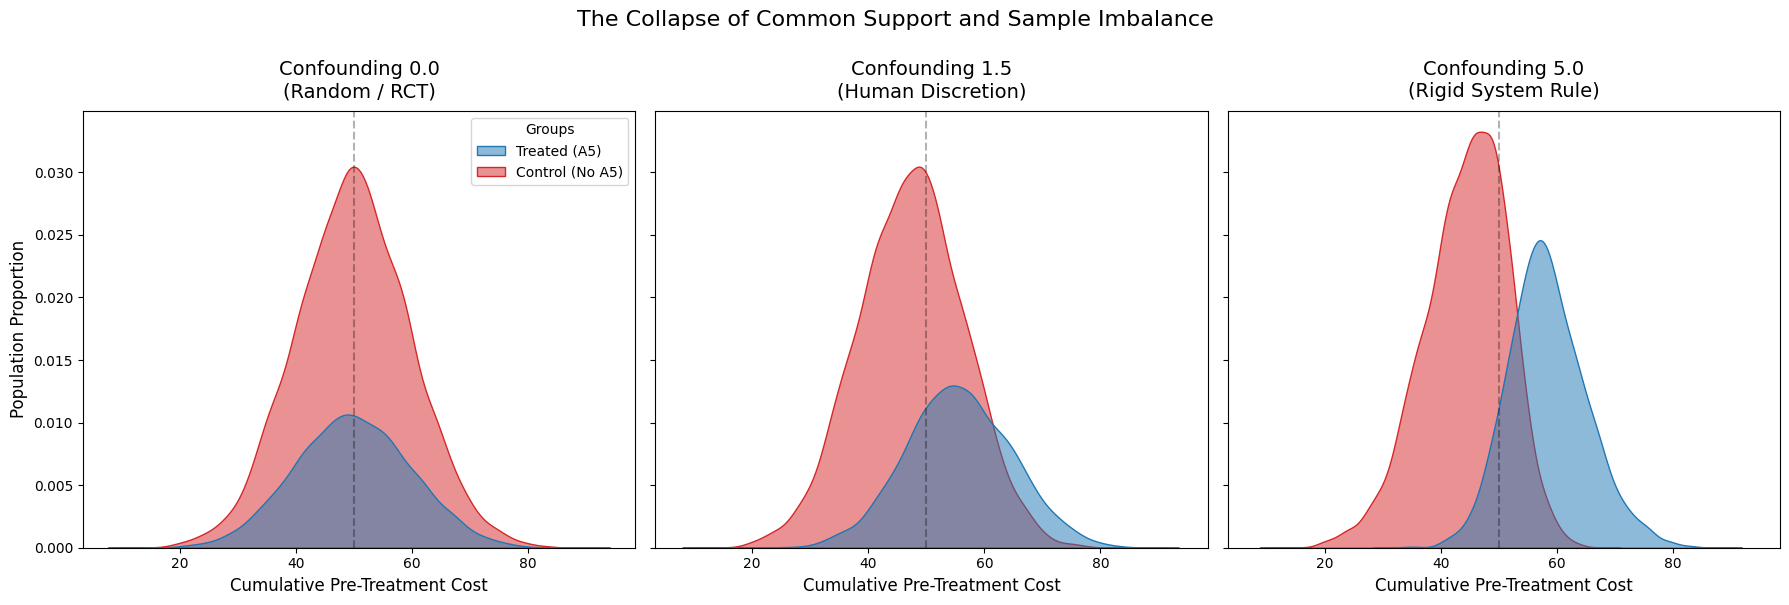

In [38]:
plot_confounding_overlap_with_counts(lang='eng')

## Discovery Tests

In [36]:
# Pass the required arguments for your data_preparation function
prep_args = {
    'case_col': case_col,
    'target_col': target_col,
    'feature_cols': feature_cols, # Insert your list
    'static_cols': static_cols, # Insert your list
    'dynamic_num_cols_sum': dynamic_num_cols_sum,
    'dynamic_num_cols_max': dynamic_num_cols_max,
    'dynamic_cat_cols': dynamic_cat_cols
}

df_benchmark_discovery = benchmark_discovery_methods(
    confounding_range=np.linspace(-5,5,41), 
    n_seeds=50, 
    top_n=10,
    top_pct=10,
    n_jobs=-1, 
    **prep_args
)

Starting parallel benchmark across 41 confounding strengths...
Total runs: 2050 (Using All CPU cores)
  -> Testing Confounding Strength: -5.0...
  -> Testing Confounding Strength: -4.75...
  -> Testing Confounding Strength: -4.5...
  -> Testing Confounding Strength: -4.25...
  -> Testing Confounding Strength: -4.0...
  -> Testing Confounding Strength: -3.75...
  -> Testing Confounding Strength: -3.5...
  -> Testing Confounding Strength: -3.25...
  -> Testing Confounding Strength: -3.0...
  -> Testing Confounding Strength: -2.75...
  -> Testing Confounding Strength: -2.5...
  -> Testing Confounding Strength: -2.25...
  -> Testing Confounding Strength: -2.0...
  -> Testing Confounding Strength: -1.75...
  -> Testing Confounding Strength: -1.5...
  -> Testing Confounding Strength: -1.25...
  -> Testing Confounding Strength: -1.0...
  -> Testing Confounding Strength: -0.75...
  -> Testing Confounding Strength: -0.5...
  -> Testing Confounding Strength: -0.25...
  -> Testing Confounding Str

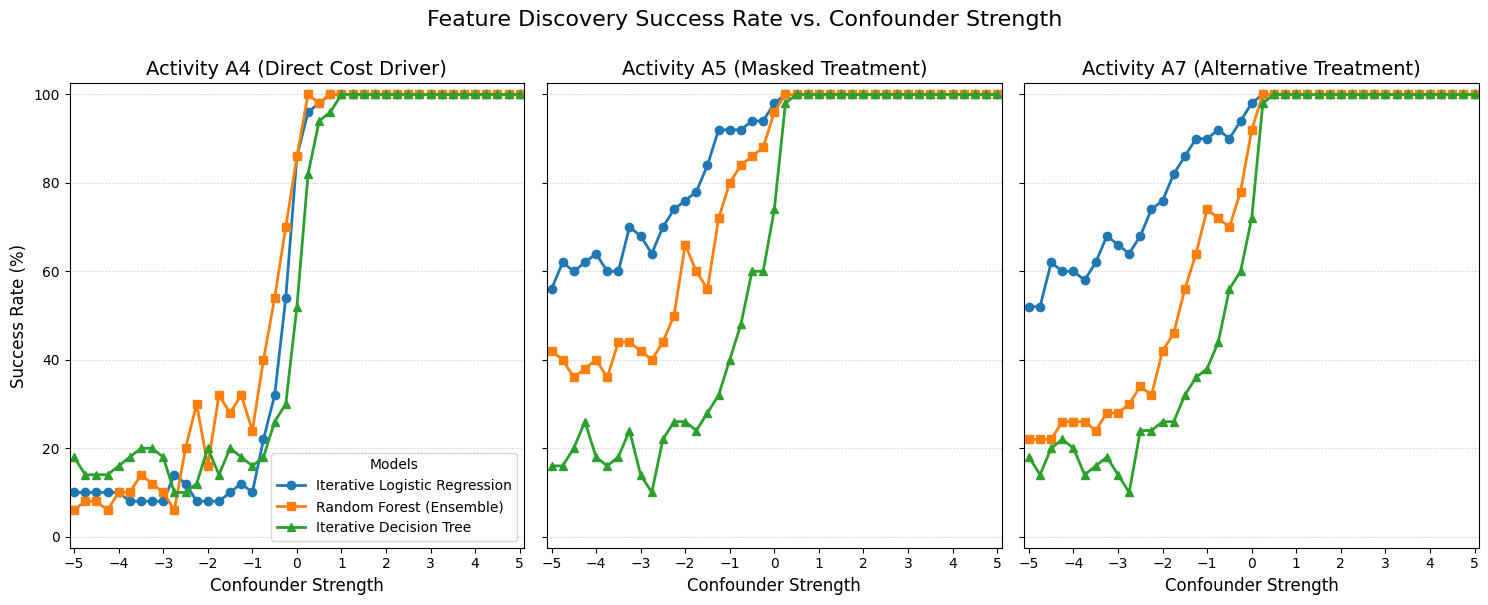

In [63]:
plot_discovery_benchmark_results(df_benchmark_discovery,lang='eng', separate_plots=False)

In [65]:
# Pass the existing presettings dictionary
prep_args = {
    'case_col': case_col,
    'target_col': target_col,
    'feature_cols': feature_cols,
    'static_cols': static_cols,
    'dynamic_num_cols_sum': dynamic_num_cols_sum,
    'dynamic_num_cols_max': dynamic_num_cols_max,
    'dynamic_cat_cols': dynamic_cat_cols
}

# 1. Generate the percentage-based grid
df_pct_a4, df_pct_a5, df_pct_a7 = benchmark_lr_top_pct_gradient(
    confounding_range=np.linspace(-5, 5, 41),
    n_seeds=50,
    n_jobs=-1,
    **prep_args
)

Starting parallel LR benchmark across 41 confounding strengths...

=== Percentage Matrix Complete ===


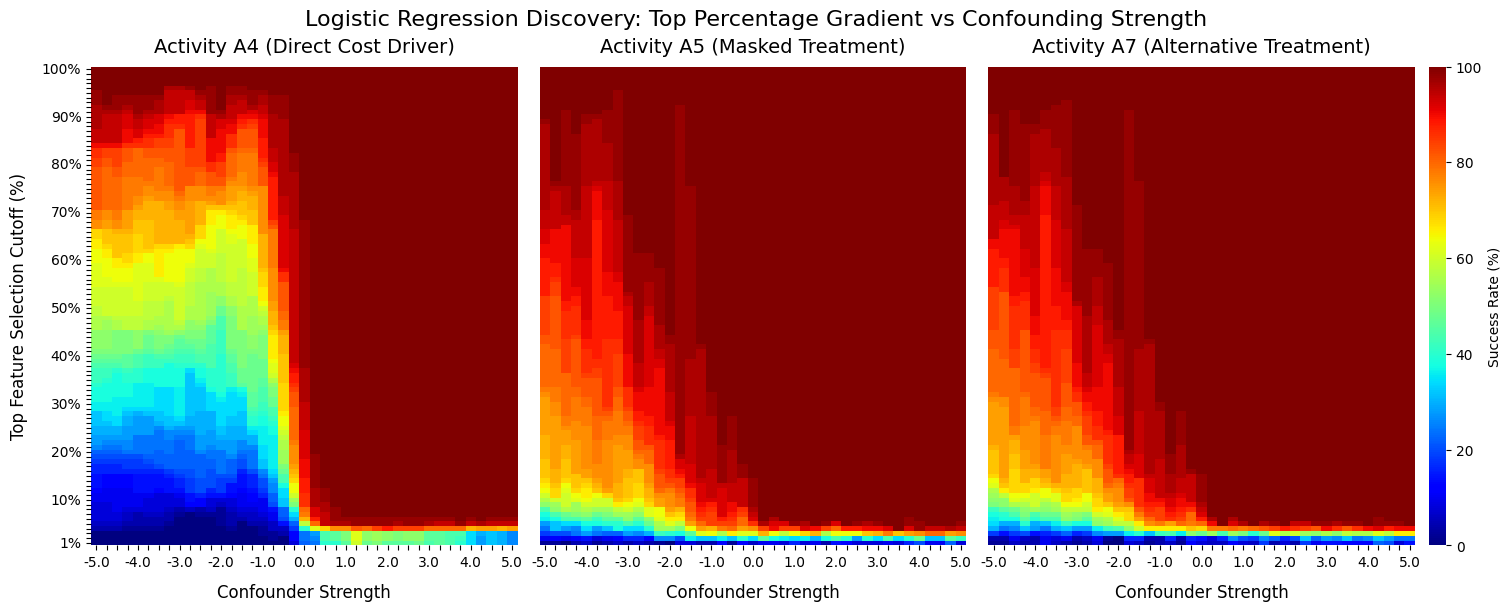

In [97]:
# 2. Render the nipy_spectral plot
plot_lr_top_pct_gradient(df_pct_a4, df_pct_a5, df_pct_a7, lang='eng', separate_plots=False)

## Causal Estimation Tests

In [35]:
df_stress_test = run_fast_confounding_stress_test(n_iterations=50)

Iniciando Teste de Stress Paralelo (50 iterações por nível)...


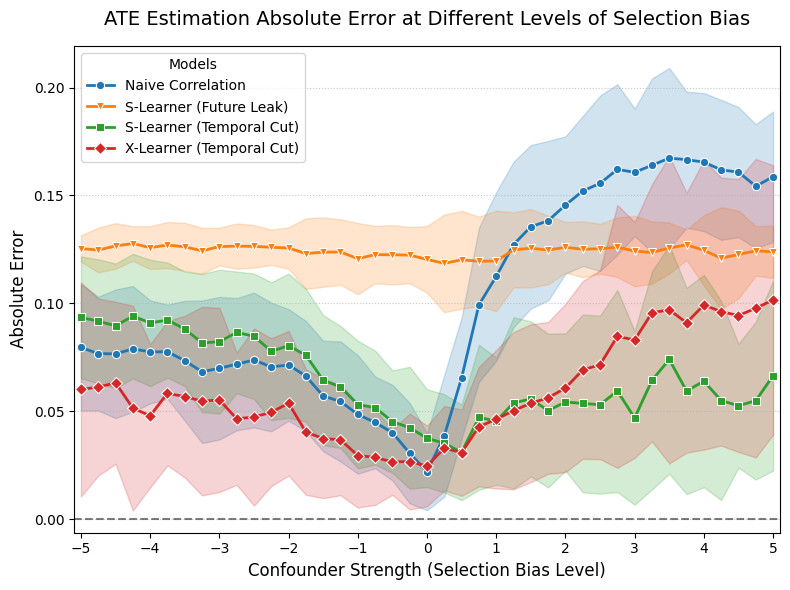

In [110]:
plot_estimation_benchmark_errors(df_stress_test,lang='eng')

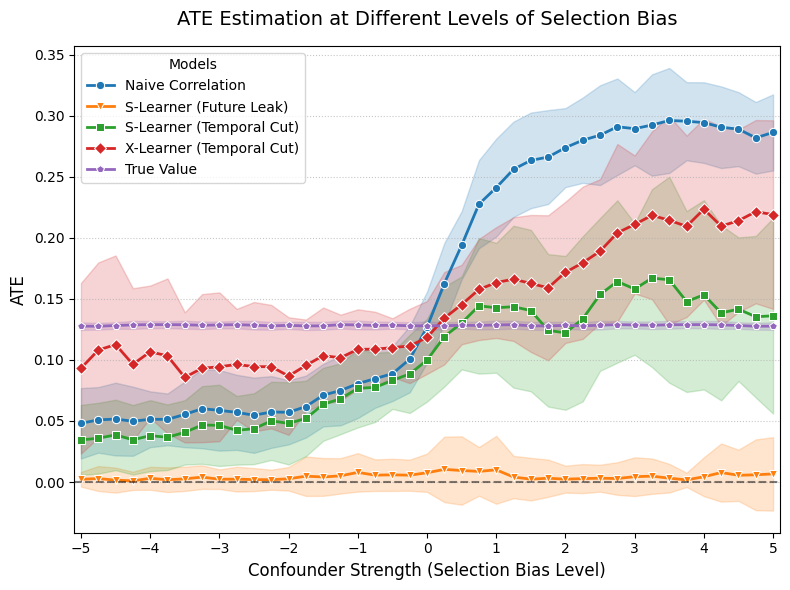

In [111]:
plot_estimation_benchmark_ATEs(df_stress_test,lang='eng')

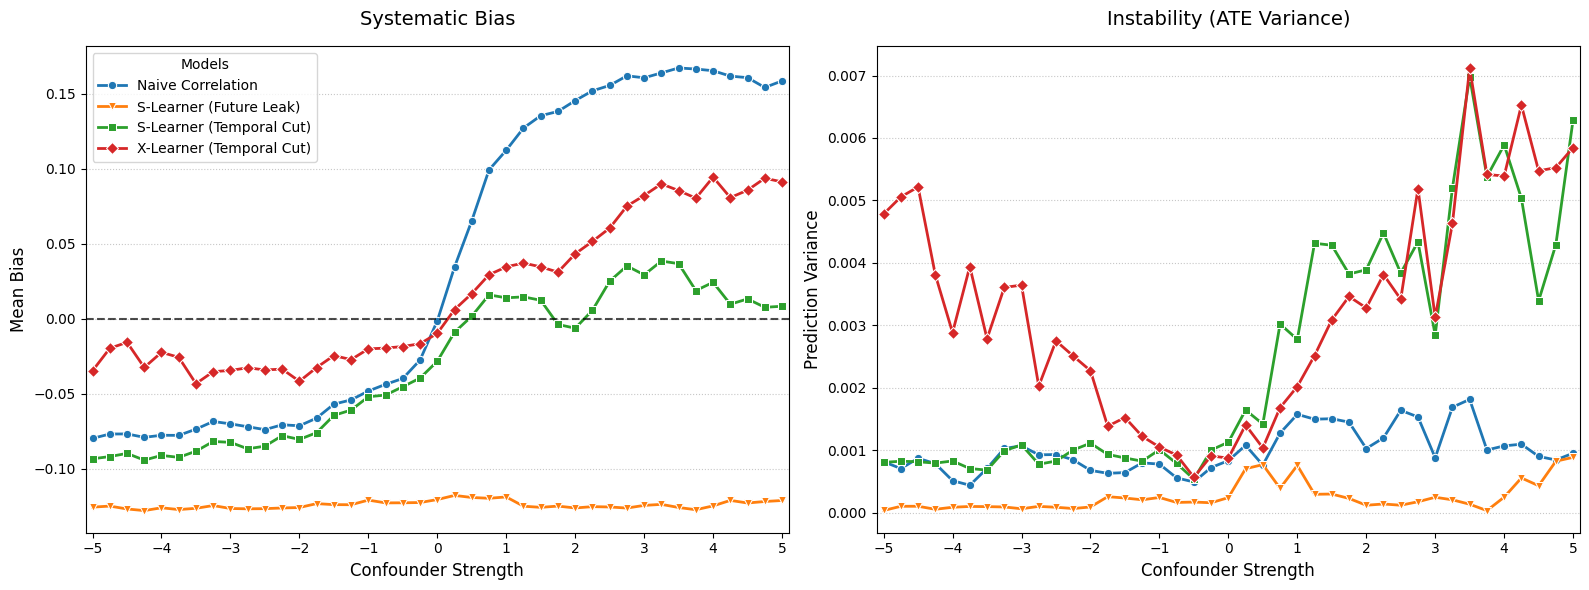

In [37]:
plot_bias_variance_tradeoff(df_stress_test,lang='eng')

## Whole Framework Test

In [114]:
df_syn, df_syn_truth = generate_advanced_test_log(n_cases=1000, confounding_strength=0, random_state=0)

In [ ]:
df_syn_raw, df_syn_cases = data_preparation(df_syn,case_col,target_col,feature_cols,static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols)

In [ ]:
rules = run_causal_discovery_pipeline(df_syn_raw, df_syn_cases, target_col, case_col, feature_cols, 
                                        static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols,
                                        candidate_prefixes=['Activity_', 'Executor_', 'Resposible For Alteration_', 'Requester_','Spurious_Tag'],
                                        invalid_contexts=['Executor_', 'Requester_', 'Resposible For Alteration_'], top_n=10, top_pct=10)

In [119]:
print(rules[rules.columns[:7]].to_markdown())

|    | Tested_Treatment   | Base_Feature   | Rule                                                                                    |   Causal Effect (ATE) | 95% Confidence Interval                                               |   Node_Samples |   Support |
|---:|:-------------------|:---------------|:----------------------------------------------------------------------------------------|----------------------:|:----------------------------------------------------------------------|---------------:|----------:|
|  0 | Activity_A4        | Activity       | Global ATE (Entire Dataset)                                                             |             0.0813241 | [np.float64(-0.00913121231376543), np.float64(0.17177946740551198)]   |            998 | 1         |
|  1 | Activity_A4        | Activity       | `Man-Hour Cost` <= 19.75968                                                             |             0.186467  | [np.float64(0.06434228361105368), np.float64(0.30859133197032

In [120]:
tables = generate_latex_tables(rules)
print(tables[0])
print(tables[1])
print(tables[2])

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|l|}
\hline
\textbf{ID} & \textbf{Feature Name} \\
\hline
\end{tabular}
\caption{Feature Dictionary mapping integer IDs to original dataset variables.}
\end{table}

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|c|p{6.5cm}|}
\hline
\textbf{Base Feature} & \textbf{Rule No.} & \textbf{Rule Logic} \\
\hline
\multirow{3}{*}{Activity\_A4} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Man-Hour Cost` $\le$ 19.76 \\
\cline{2-3}
 & R2 & `Man-Hour Cost` $>$ 19.76 \\
\hline
\multirow{6}{*}{Activity\_A7} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Activity\_A9` $>$ 0.5 $\land$ `Man-Hour Cost` $\le$ 34.475 \\
\cline{2-3}
 & R2 & `Activity\_A9` $\le$ 0.5 $\land$ `Priority` $\le$ 2.5 $\land$ `Man-Hour Cost` $\le$ 30.677 \\
\cline{2-3}
 & R3 & `Activity\_A9` $\le$ 0.5 $\land$ `Priority` $\le$ 2.5 $\land$ `Man-Hour Cost` $>$ 30.677 \\
\cline{2-3}
 & R4 & `Activity\_A9` $\le$ 0.5 $\land$ `

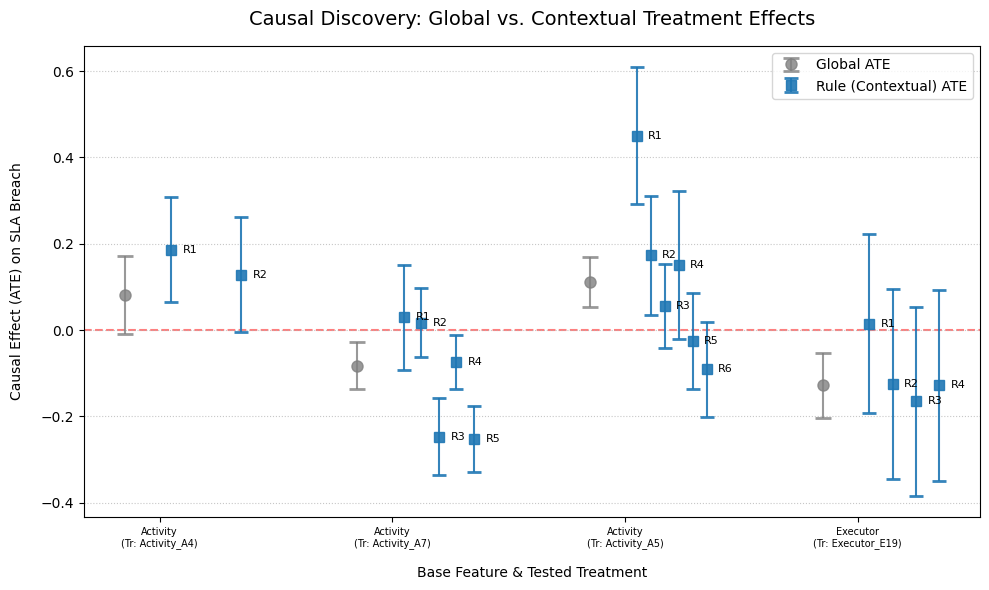

In [123]:
plot_all_causal_effects(rules, fig_name='ATE_estimation_artificial_co0-0', lang='eng')

In [124]:
df_syn, df_syn_truth = generate_advanced_test_log(n_cases=1000, confounding_strength=1.5, random_state=0)

In [ ]:
df_syn_raw, df_syn_cases = data_preparation(df_syn,case_col,target_col,feature_cols,static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols)

In [ ]:
rules = run_causal_discovery_pipeline(df_syn_raw, df_syn_cases, target_col, case_col, feature_cols, 
                                        static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols,
                                        candidate_prefixes=['Activity_', 'Executor_', 'Resposible For Alteration_', 'Requester_','Spurious_Tag'],
                                        invalid_contexts=['Executor_', 'Requester_', 'Resposible For Alteration_'], top_n=10, top_pct=10)

In [128]:
print(rules[rules.columns[:7]].to_markdown())

|    | Tested_Treatment   | Base_Feature   | Rule                                                                                        |   Causal Effect (ATE) | 95% Confidence Interval                                                |   Node_Samples |   Support |
|---:|:-------------------|:---------------|:--------------------------------------------------------------------------------------------|----------------------:|:-----------------------------------------------------------------------|---------------:|----------:|
|  0 | Activity_A4        | Activity       | Global ATE (Entire Dataset)                                                                 |             0.168822  | [np.float64(0.0762844868598368), np.float64(0.261360018449075)]        |           1000 |  1        |
|  1 | Activity_A4        | Activity       | `Man-Hour Cost` <= 19.75968                                                                 |             0.311332  | [np.float64(0.1864817701961533), np.float6

In [129]:
tables = generate_latex_tables(rules)
print(tables[0])
print(tables[1])
print(tables[2])

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|l|}
\hline
\textbf{ID} & \textbf{Feature Name} \\
\hline
\end{tabular}
\caption{Feature Dictionary mapping integer IDs to original dataset variables.}
\end{table}

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|c|p{6.5cm}|}
\hline
\textbf{Base Feature} & \textbf{Rule No.} & \textbf{Rule Logic} \\
\hline
\multirow{3}{*}{Activity\_A4} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Man-Hour Cost` $\le$ 19.76 \\
\cline{2-3}
 & R2 & `Man-Hour Cost` $>$ 19.76 \\
\hline
\multirow{7}{*}{Activity\_A5} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Man-Hour Cost` $>$ 31.94 $\land$ `Activity\_A8` $\le$ 0.5 $\land$ `Priority` $\le$ 2.5 \\
\cline{2-3}
 & R2 & `Man-Hour Cost` $>$ 31.94 $\land$ `Activity\_A8` $\le$ 0.5 $\land$ `Priority` $>$ 2.5 \\
\cline{2-3}
 & R3 & `Man-Hour Cost` $>$ 31.94 $\land$ `Activity\_A8` $>$ 0.5 \\
\cline{2-3}
 & R4 & `Man-Hour Cost` $\le$ 31.94 $\land$ `Priori

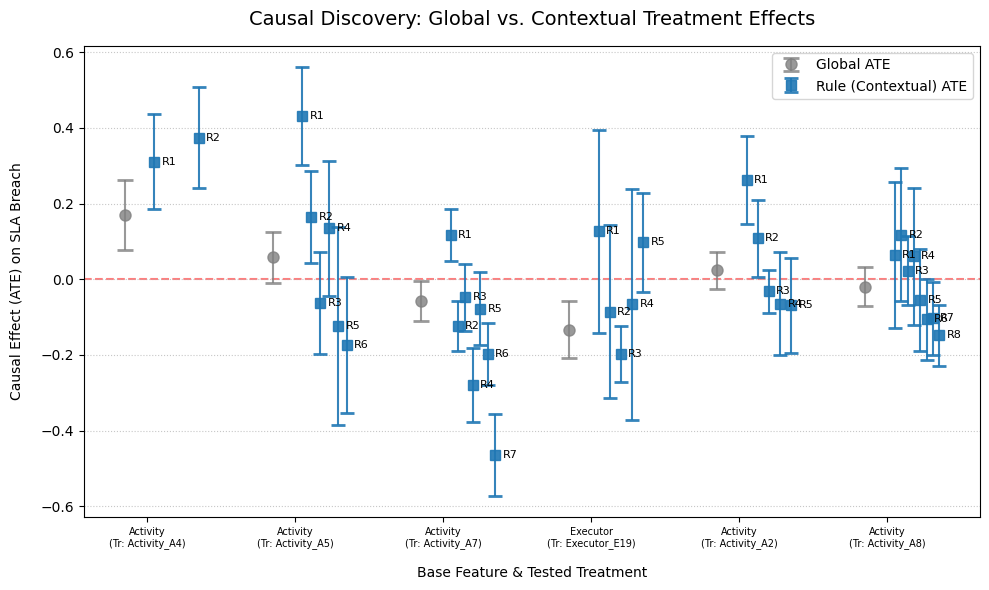

In [131]:
plot_all_causal_effects(rules, fig_name='ATE_estimation_artificial_co1-5', lang='eng')

In [132]:
df_syn, df_syn_truth = generate_advanced_test_log(n_cases=1000, confounding_strength=3, random_state=0)

In [ ]:
df_syn_raw, df_syn_cases = data_preparation(df_syn,case_col,target_col,feature_cols,static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols)

In [ ]:
rules = run_causal_discovery_pipeline(df_syn_raw, df_syn_cases, target_col, case_col, feature_cols, 
                                        static_cols, dynamic_num_cols_sum, dynamic_num_cols_max, dynamic_cat_cols,
                                        candidate_prefixes=['Activity_', 'Executor_', 'Resposible For Alteration_', 'Requester_','Spurious_Tag'],
                                        invalid_contexts=['Executor_', 'Requester_', 'Resposible For Alteration_'], top_n=10, top_pct=10)

In [135]:
print(rules[rules.columns[:7]].to_markdown())

|    | Tested_Treatment   | Base_Feature   | Rule                                                                                     |   Causal Effect (ATE) | 95% Confidence Interval                                               |   Node_Samples |   Support |
|---:|:-------------------|:---------------|:-----------------------------------------------------------------------------------------|----------------------:|:----------------------------------------------------------------------|---------------:|----------:|
|  0 | Activity_A4        | Activity       | Global ATE (Entire Dataset)                                                              |            0.27489    | [np.float64(0.18331371169272492), np.float64(0.3664663114149791)]     |           1000 |  1        |
|  1 | Activity_A4        | Activity       | `Man-Hour Cost` <= 19.75968                                                              |            0.360978   | [np.float64(0.23645673000804637), np.float64(0.4854995761

In [136]:
tables = generate_latex_tables(rules)
print(tables[0])
print(tables[1])
print(tables[2])

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|l|}
\hline
\textbf{ID} & \textbf{Feature Name} \\
\hline
\end{tabular}
\caption{Feature Dictionary mapping integer IDs to original dataset variables.}
\end{table}

\begin{table}[!h]
\centering
\fontsize{6}{7.5}\selectfont
\begin{tabular}{|l|c|p{6.5cm}|}
\hline
\textbf{Base Feature} & \textbf{Rule No.} & \textbf{Rule Logic} \\
\hline
\multirow{3}{*}{Activity\_A4} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Man-Hour Cost` $\le$ 19.76 \\
\cline{2-3}
 & R2 & `Man-Hour Cost` $>$ 19.76 \\
\hline
\multirow{4}{*}{Activity\_A5} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Activity\_A2` $>$ 0.5 $\land$ `Man-Hour Cost` $\le$ 34.422 \\
\cline{2-3}
 & R2 & `Activity\_A2` $>$ 0.5 $\land$ `Man-Hour Cost` $>$ 34.422 \\
\cline{2-3}
 & R3 & `Activity\_A2` $\le$ 0.5 \\
\hline
\multirow{4}{*}{Activity\_A7} & Global & Entire Dataset \\
\cline{2-3}
 & R1 & `Priority` $\le$ 2.5 \\
\cline{2-3}
 & R2 & `Priority` $>$ 2.5 $\

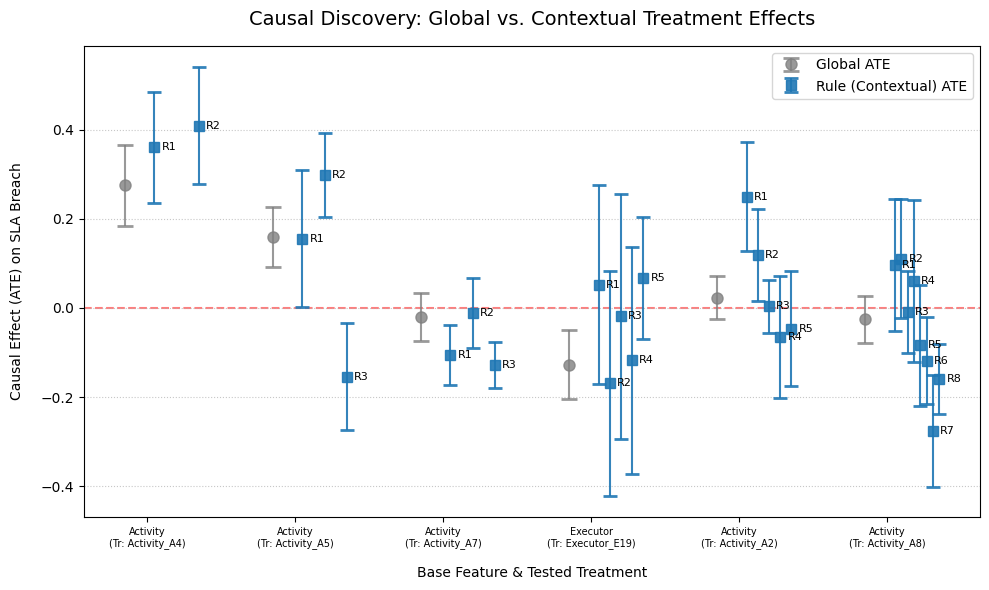

In [138]:
plot_all_causal_effects(rules, fig_name='ATE_estimation_artificial_co3-0', lang='eng')